# 📊 Impacto de las redes sociales en los estudiantes

**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión · Trabajo práctico grupal**

Este notebook reúne en un único documento los análisis realizados por los integrantes del grupo sobre el dataset *Students Social Media Addiction* (`data/raw/dataset_final`). El contenido de cada análisis (código, resultados y gráficos) se conserva tal como fue generado; únicamente se ordenó y se agregaron textos de introducción y enlace entre secciones para facilitar la lectura.

### Estructura del notebook

| Parte | Tema | Pregunta de investigación |
|---|---|---|
| 1 | Preparación y exploración general | Carga del dataset, calidad de los datos y tratamiento de `Relationship_Status` |
| 2 | Edad y nivel de desarrollo del país | ¿El impacto de las redes sociales es igual para todos los estudiantes según su edad y el nivel de desarrollo de su país? |
| 3 | Sueño y rendimiento académico | ¿El uso de redes sociales impacta en el sueño y en el rendimiento académico? |
| 4 | Horas de uso por red social y edad | ¿Cuántas horas le dedican los estudiantes a cada red social según su edad? ¿Cómo se relaciona con la salud mental? |
| 5 | Plataformas y brecha de género | ¿Hay redes sociales que impactan más que otras y existe una brecha de género en ese impacto? |
| 6 | Relaciones sentimentales | ¿El uso de redes sociales afecta las relaciones sentimentales de los estudiantes? |
| 7 | Síntesis final | Resumen de las respuestas encontradas |

> **Nota sobre la ejecución:** cada parte vuelve a cargar el dataset original y aplica sus propias transformaciones (por ejemplo, la Parte 5 elimina filas duplicadas y la Parte 6 conserva `Relationship_Status`). De esta manera cada análisis es reproducible por sí mismo y los resultados de una parte no alteran los de las demás.

**Criterio común de interpretación:** en todo el trabajo un valor más alto de `Mental_Health_Score` representa un **mejor** estado de salud mental.

---

# Parte 1 | Preparación y exploración general del dataset

En esta parte se importan las librerías, se carga el dataset y se realiza una primera inspección general: estructura, tipos de datos, valores faltantes y duplicados. Las conclusiones de esta exploración (en particular, la gran cantidad de faltantes en `Relationship_Status`) son la base de las decisiones de limpieza que toma cada análisis posterior.

## 1.1 | Preparación del análisis

En esta primera etapa se importan las librerías necesarias y se carga el dataset utilizado en el trabajo.

El objetivo es verificar que los datos hayan sido importados correctamente y conocer su estructura antes de comenzar con el análisis.

In [ ]:
# Cargo todas las librerias necesarias para procesar los datos.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Cargamos directamente el dataset elegido desde nuestro repositorio.

url = "https://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/Facu/data/raw/dataset_final"

df = pd.read_csv(url)

## 1.2 | Exploración inicial del dataset

Antes de analizar las preguntas de investigación, se realiza una inspección general del conjunto de datos.

Se busca identificar:

- cantidad de observaciones y variables;
- tipo de cada variable;
- presencia de valores faltantes;
- posibles duplicados;
- distribución inicial de las variables relevantes.

Esta etapa permite detectar problemas de calidad de datos y definir qué transformaciones serán necesarias para el análisis posterior.

In [ ]:
# Muestro las primeras filas de nuestro dataset

df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


In [ ]:
# Muestro las ultimas filas de nuestro dataset

df.tail()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1738,701,20,Female,Undergraduate,Italy,4.7,TikTok,No,7.2,7.0,In Relationship
1739,702,23,Male,Graduate,Russia,6.8,Instagram,Yes,5.9,4.0,Single
1740,703,21,Female,Undergraduate,China,5.6,WeChat,Yes,6.7,6.0,In Relationship
1741,704,24,Male,Graduate,Japan,4.3,Twitter,No,7.5,8.0,Single
1742,705,19,Female,Undergraduate,Poland,6.2,Facebook,Yes,6.3,5.0,Single


In [ ]:
# Definimos que tipo de datos tienen nuestro dataset

df.dtypes

,0
Student_ID,int64
Age,int64
Gender,object
Academic_Level,object
Country,object
Avg_Daily_Usage_Hours,float64
Most_Used_Platform,object
Affects_Academic_Performance,object
Sleep_Hours_Per_Night,float64
Mental_Health_Score,float64


In [ ]:
# Valores faltantes
df.isna().sum().sort_values(ascending=False)

,0
Relationship_Status,1038
Age,0
Student_ID,0
Gender,0
Academic_Level,0
Avg_Daily_Usage_Hours,0
Country,0
Most_Used_Platform,0
Affects_Academic_Performance,0
Sleep_Hours_Per_Night,0


In [ ]:
# Registros duplicados
print("Duplicados:", df.duplicated().sum())

Duplicados: 0


### Tratamiento de la variable `Relationship_Status`

Durante la exploración inicial se observó una cantidad considerable de valores faltantes en la variable `Relationship_Status`.

Dado que esta variable no resulta indispensable para responder las preguntas principales del análisis —centradas en las diferencias según la edad de los estudiantes y el nivel de desarrollo de sus países— se decidió excluirla del conjunto de variables utilizadas.

Esta decisión permite simplificar el análisis sin eliminar observaciones completas del dataset únicamente por la ausencia de información sobre el estado de relación del estudiante.

In [ ]:
faltantes_relationship = df["Relationship_Status"].isna().sum()
porcentaje_relationship = df["Relationship_Status"].isna().mean() * 100

print("Valores faltantes:", faltantes_relationship)
print(f"Porcentaje de faltantes: {porcentaje_relationship:.2f}%")

Valores faltantes: 1038
Porcentaje de faltantes: 59.55%


In [ ]:
df = df.drop(columns=["Relationship_Status"]) # Elimina únicamente la columna Relationship_Status, pero mantiene todas las filas del dataset.

In [ ]:
df.columns # Verificamos que efectivamente desapareció

Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country',
       'Avg_Daily_Usage_Hours', 'Most_Used_Platform',
       'Affects_Academic_Performance', 'Sleep_Hours_Per_Night',
       'Mental_Health_Score'],
      dtype='object')

In [ ]:
# Mostramos estadisticas descriptivas de las columnas numericas del dataframe que efectivamente vamos a usar
df.describe()

,Student_ID,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,1743.000000,1743.000000,1743.000000,1743.000000,1743.000000
mean,381.694205,20.725760,4.980034,6.781239,6.212909
std,228.749646,1.507523,1.395759,1.155781,1.152245
min,1.000000,18.000000,1.500000,3.800000,4.000000
25%,188.500000,19.000000,4.000000,5.900000,5.000000
50%,376.000000,21.000000,4.800000,6.800000,6.000000
75%,562.000000,22.000000,5.900000,7.600000,7.000000
max,1000.000000,24.000000,8.500000,9.600000,9.000000


---

# Parte 2 | ¿El impacto es igual para todos los estudiantes? Edad y nivel de desarrollo del país

Esta parte continúa directamente sobre el `df` preparado en la Parte 1 (sin `Relationship_Status` y con todas las filas). Se analizan dos posibles fuentes de diferencias en el impacto de las redes sociales:

- la **edad** del estudiante, agrupada en rangos (`Grupo_Edad`);
- el **nivel de desarrollo** del país donde vive, según la clasificación por ingreso del Banco Mundial (`Nivel_Desarrollo`).

## 2.1 | Pregunta de investigación

### ¿Cuál es la pregunta?

**¿Existen diferencias en el impacto de las redes sociales sobre los estudiantes según su edad y según el nivel de desarrollo del país en el que viven?**

Para abordar esta pregunta se analizarán variables relacionadas con el uso de redes sociales, el bienestar de los estudiantes y su desempeño académico, comparándolas entre distintos grupos etarios y entre países con diferentes niveles de desarrollo.

### ¿Por qué vale la pena responderla?

El uso de redes sociales forma parte de la vida cotidiana de los estudiantes, pero su impacto puede no ser igual para todos. La edad puede estar asociada con diferentes hábitos de uso, niveles de dependencia y efectos sobre el bienestar o el rendimiento académico.

Al mismo tiempo, el contexto socioeconómico del país puede influir en el acceso a la tecnología, los hábitos digitales y las consecuencias asociadas al uso de redes sociales.

Analizar estas diferencias permite identificar si determinados grupos presentan patrones particulares y comprender mejor qué características pueden estar relacionadas con un mayor o menor impacto de las redes sociales.

### ¿Qué respuesta encontramos?

Esta sección será completada al finalizar el análisis, utilizando los resultados estadísticos y gráficos obtenidos en las siguientes etapas del trabajo.

## 2.2 | Agrupación de edades

Para facilitar la comparación entre estudiantes de distintas edades, se creó una nueva variable categórica denominada `Grupo_Edad`.

Las edades originales, comprendidas entre 18 y 24 años, se agruparon en tres rangos: **18-20**, **21-22** y **23-24 años**. Esta transformación permite resumir la información y comparar de manera más clara posibles diferencias entre grupos etarios.

In [ ]:
# Contamos cuantos estudiantes hay de cada edad

df["Age"].value_counts().sort_index()

# Nos permite verificar que no haya una edad con muy pocos casos. Si un grupo queda demasiado chico, la comparación podría ser poco representativa.

,count
Age,
18,67
19,373
20,379
21,372
22,344
23,120
24,88


In [ ]:
# Creamos tres grupos de edad:
# 18-20 años, 21-22 años y 23-24 años

df["Grupo_Edad"] = pd.cut( # pd.cut(): toma una variable numérica continua, en este caso Age, y la transforma en categorías.
    df["Age"],
    bins=[17, 20, 22, 24], # Definimos los limites
    labels=["18-20", "21-22", "23-24"]
)

In [ ]:
# Revisamos cuántos estudiantes quedaron en cada grupo
df["Grupo_Edad"].value_counts().sort_index()

,count
Grupo_Edad,
18-20,819
21-22,716
23-24,208


La agrupación por edades muestra una distribución desigual entre los tres grupos definidos. La mayor cantidad de observaciones corresponde a estudiantes de **18 a 20 años (819 casos)**, seguida por el grupo de **21 a 22 años (716 casos)**. En cambio, el grupo de **23 a 24 años** cuenta con una cantidad considerablemente menor de observaciones (**208 casos**).

Esta diferencia en el tamaño de los grupos debe tenerse en cuenta al interpretar los resultados, ya que los estadísticos del grupo de mayor edad pueden ser menos estables debido a su menor cantidad de observaciones.

## 2.3 | Clasificación de países según nivel de desarrollo

Para analizar si el impacto de las redes sociales presenta diferencias entre países, se creará una nueva variable denominada `Nivel_Desarrollo`.

Esta variable permitirá agrupar los países del dataset en categorías según su nivel de desarrollo, facilitando posteriormente la comparación de indicadores relacionados con el uso de redes sociales, bienestar y desempeño académico.

In [ ]:
# Mostramos todos los países del dataset sin que Pandas oculte filas
paises = df["Country"].value_counts()

print(paises.to_string())

Country
India              192
USA                155
Canada             112
UK                  88
Australia           80
Germany             60
Spain               54
Mexico              54
France              54
Switzerland         54
Turkey              54
Ireland             54
Denmark             54
Japan               42
Russia              42
Italy               42
Bangladesh          40
Nepal               38
Pakistan            38
Maldives            38
Sri Lanka           38
China               32
Poland              32
South Korea         26
UAE                 16
Singapore           16
New Zealand         16
Brazil              16
Malaysia            16
Netherlands         16
Finland             16
Austria              2
Thailand             2
Philippines          2
Taiwan               2
Indonesia            2
Hong Kong            2
Israel               2
Egypt                2
Morocco              2
Vietnam              2
Belgium              2
Greece               2
Por

In [ ]:
# Obtenemos una lista con los países únicos del dataset
paises_unicos = sorted(df["Country"].dropna().unique())

print(paises_unicos)
print("Cantidad de países:", len(paises_unicos))

['Afghanistan', 'Albania', 'Andorra', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Bhutan', 'Bolivia', 'Bosnia', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'China', 'Colombia', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Ecuador', 'Egypt', 'Estonia', 'Finland', 'France', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kuwait', 'Kyrgyzstan', 'Latvia', 'Lebanon', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Malaysia', 'Maldives', 'Malta', 'Mexico', 'Moldova', 'Monaco', 'Montenegro', 'Morocco', 'Nepal', 'Netherlands', 'New Zealand', 'Nigeria', 'North Macedonia', 'Norway', 'Oman', 'Pakistan', 'Panama', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Qatar', 'Romania', 'Russia', 'San Marino', 'Serbia', 'Singapore', 'Slovakia', 'Slovenia',

### Criterio para clasificar los países

Para clasificar los países se utilizó como referencia la **clasificación por nivel de ingreso del Banco Mundial**, ya que es una fuente internacional estandarizada y actualizada periódicamente que permite comparar economías bajo un mismo criterio.

El Banco Mundial divide a las economías en cuatro grupos según su **Ingreso Nacional Bruto (GNI) per cápita**: ingreso bajo, ingreso medio-bajo, ingreso medio-alto e ingreso alto. Para simplificar el análisis de este trabajo, se agruparon las economías de **ingreso alto** bajo la categoría **“Desarrollado”**, mientras que las restantes se incluyeron en **“En desarrollo”**.

Se eligió este criterio porque permite construir una clasificación reproducible y menos subjetiva que una asignación manual país por país. De todos modos, se reconoce que el nivel de ingreso no representa por sí solo todas las dimensiones del desarrollo económico y social, por lo que esta simplificación constituye una limitación del análisis.

In [ ]:
# Clasificamos los países según el nivel de ingreso del Banco Mundial.
# "Desarrollado" = economías de ingreso alto
# "En desarrollo" = economías de ingreso bajo, medio-bajo o medio-alto

clasificacion_paises = {

    # Desarrollados
    "Andorra": "Desarrollado",
    "Australia": "Desarrollado",
    "Austria": "Desarrollado",
    "Bahamas": "Desarrollado",
    "Bahrain": "Desarrollado",
    "Belgium": "Desarrollado",
    "Bulgaria": "Desarrollado",
    "Canada": "Desarrollado",
    "Chile": "Desarrollado",
    "Costa Rica": "Desarrollado",
    "Croatia": "Desarrollado",
    "Cyprus": "Desarrollado",
    "Czech Republic": "Desarrollado",
    "Denmark": "Desarrollado",
    "Estonia": "Desarrollado",
    "Finland": "Desarrollado",
    "France": "Desarrollado",
    "Germany": "Desarrollado",
    "Greece": "Desarrollado",
    "Hong Kong": "Desarrollado",
    "Hungary": "Desarrollado",
    "Iceland": "Desarrollado",
    "Ireland": "Desarrollado",
    "Israel": "Desarrollado",
    "Italy": "Desarrollado",
    "Japan": "Desarrollado",
    "Kuwait": "Desarrollado",
    "Latvia": "Desarrollado",
    "Liechtenstein": "Desarrollado",
    "Lithuania": "Desarrollado",
    "Luxembourg": "Desarrollado",
    "Malta": "Desarrollado",
    "Monaco": "Desarrollado",
    "Netherlands": "Desarrollado",
    "New Zealand": "Desarrollado",
    "Norway": "Desarrollado",
    "Oman": "Desarrollado",
    "Panama": "Desarrollado",
    "Poland": "Desarrollado",
    "Portugal": "Desarrollado",
    "Qatar": "Desarrollado",
    "Romania": "Desarrollado",
    "Russia": "Desarrollado",
    "San Marino": "Desarrollado",
    "Singapore": "Desarrollado",
    "Slovakia": "Desarrollado",
    "Slovenia": "Desarrollado",
    "South Korea": "Desarrollado",
    "Spain": "Desarrollado",
    "Sweden": "Desarrollado",
    "Switzerland": "Desarrollado",
    "Taiwan": "Desarrollado",
    "Trinidad": "Desarrollado",
    "UAE": "Desarrollado",
    "UK": "Desarrollado",
    "USA": "Desarrollado",
    "Uruguay": "Desarrollado",

    # En desarrollo
    "Afghanistan": "En desarrollo",
    "Albania": "En desarrollo",
    "Argentina": "En desarrollo",
    "Armenia": "En desarrollo",
    "Azerbaijan": "En desarrollo",
    "Bangladesh": "En desarrollo",
    "Belarus": "En desarrollo",
    "Bhutan": "En desarrollo",
    "Bolivia": "En desarrollo",
    "Bosnia": "En desarrollo",
    "Brazil": "En desarrollo",
    "China": "En desarrollo",
    "Colombia": "En desarrollo",
    "Ecuador": "En desarrollo",
    "Egypt": "En desarrollo",
    "Georgia": "En desarrollo",
    "Ghana": "En desarrollo",
    "India": "En desarrollo",
    "Indonesia": "En desarrollo",
    "Iraq": "En desarrollo",
    "Jamaica": "En desarrollo",
    "Jordan": "En desarrollo",
    "Kazakhstan": "En desarrollo",
    "Kenya": "En desarrollo",
    "Kosovo": "En desarrollo",
    "Kyrgyzstan": "En desarrollo",
    "Lebanon": "En desarrollo",
    "Malaysia": "En desarrollo",
    "Maldives": "En desarrollo",
    "Mexico": "En desarrollo",
    "Moldova": "En desarrollo",
    "Montenegro": "En desarrollo",
    "Morocco": "En desarrollo",
    "Nepal": "En desarrollo",
    "Nigeria": "En desarrollo",
    "North Macedonia": "En desarrollo",
    "Pakistan": "En desarrollo",
    "Paraguay": "En desarrollo",
    "Peru": "En desarrollo",
    "Philippines": "En desarrollo",
    "Serbia": "En desarrollo",
    "South Africa": "En desarrollo",
    "Sri Lanka": "En desarrollo",
    "Syria": "En desarrollo",
    "Tajikistan": "En desarrollo",
    "Thailand": "En desarrollo",
    "Turkey": "En desarrollo",
    "Ukraine": "En desarrollo",
    "Uzbekistan": "En desarrollo",
    "Venezuela": "En desarrollo",
    "Vietnam": "En desarrollo",
    "Yemen": "En desarrollo"
}

In [ ]:
# Creamos la nueva variable Nivel_Desarrollo utilizando la clasificación definida anteriormente.

df["Nivel_Desarrollo"] = df["Country"].map(clasificacion_paises)

In [ ]:
# Revisamos si algún país no pudo ser clasificado.

df[df["Nivel_Desarrollo"].isna()]["Country"].unique()

array(['Vatican City'], dtype=object)

Acá hay un caso especial: Vatican City. El Banco Mundial no lo incluye normalmente dentro de esta clasificación por ingreso, por lo que yo no lo asignaría arbitrariamente a uno de los dos grupos. Lo dejaría como faltante en Nivel_Desarrollo y lo excluiría únicamente de las comparaciones que utilicen esta variable.

In [ ]:
# Observamos cuántos estudiantes quedaron en cada grupo.

df["Nivel_Desarrollo"].value_counts(dropna=False)

,count
Nivel_Desarrollo,
Desarrollado,1103
En desarrollo,638
NaN,2


La clasificación por nivel de desarrollo permitió agrupar a la mayoría de los estudiantes en dos categorías: **1.103 estudiantes de países desarrollados** y **638 estudiantes de países en desarrollo**.

La distribución no es completamente equilibrada, ya que el grupo de países desarrollados tiene una mayor cantidad de observaciones. Esta diferencia deberá tenerse en cuenta al interpretar los resultados, especialmente en comparaciones gráficas o estadísticas entre ambos grupos.

Además, quedaron **2 observaciones sin clasificar**, correspondientes a países que no pudieron ser asignados mediante el criterio utilizado.

## 2.4 | Comparación de indicadores mediante agrupaciones

Una vez realizadas las transformaciones necesarias, se agrupan los estudiantes según las nuevas variables `Grupo_Edad` y `Nivel_Desarrollo`.

A partir de estas agrupaciones se calcularán estadísticos de resumen, como la **media** y la **mediana**, sobre distintas variables relacionadas con el impacto de las redes sociales.

Este análisis permitirá observar si existen diferencias entre los grupos etarios y entre estudiantes de países con distinto nivel de desarrollo.

In [ ]:
# Resumimos los principales indicadores según el grupo de edad.
# Esto nos permite comparar en una misma tabla el uso de redes,
# las horas de sueño y el puntaje de salud mental.

resumen_edad = df.groupby("Grupo_Edad")[
    ["Avg_Daily_Usage_Hours",
     "Sleep_Hours_Per_Night",
     "Mental_Health_Score"]
].agg(["mean", "median"]).round(2)

resumen_edad

/tmp/ipykernel_8850/355211931.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumen_edad = df.groupby("Grupo_Edad")[


Avg_Daily_Usage_Hours        Sleep_Hours_Per_Night         \
                            mean median                  mean median   
Grupo_Edad                                                             
18-20                       5.09    4.9                  6.68    6.6   
21-22                       4.91    4.7                  6.90    6.9   
23-24                       4.81    4.8                  6.75    7.0   

           Mental_Health_Score         
                          mean median  
Grupo_Edad                             
18-20                     6.10    6.0  
21-22                     6.28    6.0  
23-24                     6.44    6.5

In [ ]:
# Resumimos los principales indicadores según
# el nivel de desarrollo del país.

resumen_desarrollo = df.groupby("Nivel_Desarrollo")[
    ["Avg_Daily_Usage_Hours",
     "Sleep_Hours_Per_Night",
     "Mental_Health_Score"]
].agg(["mean", "median"]).round(2)

resumen_desarrollo

Avg_Daily_Usage_Hours        Sleep_Hours_Per_Night         \
                                  mean median                  mean median   
Nivel_Desarrollo                                                             
Desarrollado                      4.83    4.6                  6.97    7.1   
En desarrollo                     5.25    5.2                  6.45    6.3   

                 Mental_Health_Score         
                                mean median  
Nivel_Desarrollo                             
Desarrollado                    6.37    6.3  
En desarrollo                   5.94    6.0

In [ ]:
# Calculamos la proporción de respuestas dentro de cada grupo de edad.

pd.crosstab(
    df["Grupo_Edad"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

Affects_Academic_Performance,No,Yes
Grupo_Edad,,
18-20,33.089133,66.910867
21-22,36.731844,63.268156
23-24,52.403846,47.596154


In [ ]:
# Comparamos el impacto académico percibido
# según el nivel de desarrollo del país.

pd.crosstab(
    df["Nivel_Desarrollo"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

Affects_Academic_Performance,No,Yes
Nivel_Desarrollo,,
Desarrollado,43.517679,56.482321
En desarrollo,25.548589,74.451411


### Criterio de interpretación

Para este análisis se considera que un valor más alto de `Mental_Health_Score` representa un mejor estado de salud mental.

Por lo tanto, al comparar grupos, un puntaje promedio más bajo será interpretado como un indicador menos favorable de bienestar mental.

### Interpretación de los resultados

Los resultados descriptivos sugieren que el grupo de **18 a 20 años** presenta, en términos generales, los indicadores más desfavorables entre los grupos etarios analizados. Esta conclusión se basa en la comparación conjunta de variables relacionadas con el tiempo de uso de redes sociales, las horas de sueño, la salud mental y el impacto académico percibido.

De manera similar, los estudiantes pertenecientes a **países en desarrollo** muestran resultados menos favorables en varios de estos indicadores en comparación con aquellos de países desarrollados.

Estos resultados describen diferencias observadas dentro de la muestra y no permiten establecer relaciones causales.

## 2.5 | Visualización de resultados

Para complementar el análisis descriptivo, se utilizan gráficos que permiten comparar visualmente los principales indicadores según el grupo de edad y el nivel de desarrollo del país.

Las visualizaciones se centran en las variables vinculadas con el uso de redes sociales, las horas de sueño, la salud mental y el impacto académico percibido.

### 2.5.1 | Uso diario de redes sociales según grupo de edad

En este gráfico se compara el **promedio de horas diarias de uso de redes sociales** entre los distintos grupos etarios.

El objetivo es identificar si existen diferencias en la intensidad de uso según la edad de los estudiantes y observar qué grupo presenta una mayor exposición diaria a las redes sociales.

---

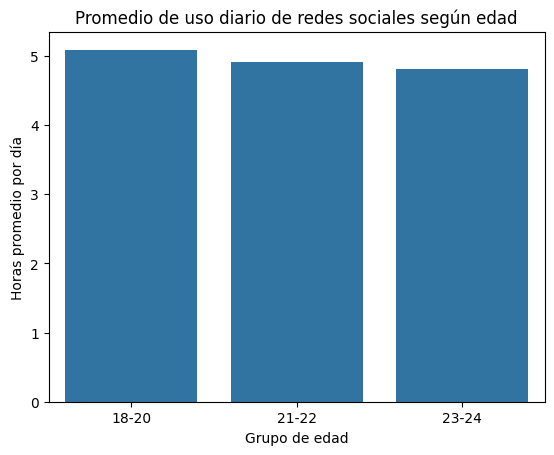

In [ ]:
# Calculamos el promedio de horas diarias de uso
# para cada grupo de edad.

uso_edad = (
    df.groupby("Grupo_Edad", observed=True)["Avg_Daily_Usage_Hours"]
      .mean()
      .reset_index()
)

# Creamos el gráfico
sns.barplot(
    data=uso_edad,
    x="Grupo_Edad",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Promedio de uso diario de redes sociales según edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Horas promedio por día")
plt.show()

### 2.5.2 | Salud mental según grupo de edad

A continuación se compara el **puntaje promedio de salud mental** entre los grupos de edad definidos.

Considerando que un valor más alto de `Mental_Health_Score` representa una mejor salud mental, el gráfico permite identificar qué grupos presentan resultados relativamente más favorables o desfavorables en este indicador.

---

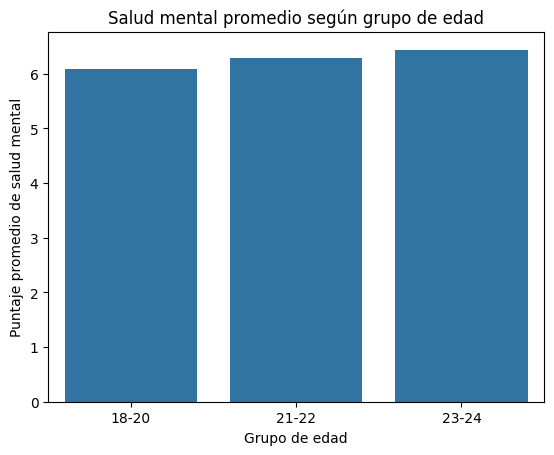

In [ ]:
# Calculamos el puntaje promedio de salud mental
# para cada grupo de edad.

salud_edad = (
    df.groupby("Grupo_Edad", observed=True)["Mental_Health_Score"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=salud_edad,
    x="Grupo_Edad",
    y="Mental_Health_Score"
)

plt.title("Salud mental promedio según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Puntaje promedio de salud mental")
plt.show()

### 2.5.3 | Uso diario de redes sociales según nivel de desarrollo

Este gráfico compara el **promedio de horas diarias de uso de redes sociales** entre estudiantes de países desarrollados y países en desarrollo.

La visualización permite analizar si el nivel de desarrollo del país está asociado con diferencias en la intensidad de uso de las redes sociales.

---

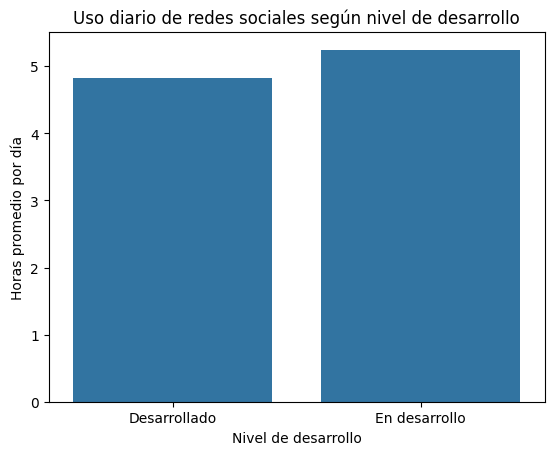

In [ ]:
# Calculamos el promedio de uso diario según
# el nivel de desarrollo del país.

uso_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Avg_Daily_Usage_Hours"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=uso_desarrollo,
    x="Nivel_Desarrollo",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Uso diario de redes sociales según nivel de desarrollo")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Horas promedio por día")
plt.show()

**Interpretación:**  
El gráfico muestra diferencias en el promedio de horas diarias de uso de redes sociales entre estudiantes de países desarrollados y en desarrollo. Los estudiantes pertenecientes a **países en desarrollo presentan un mayor promedio de uso diario**, lo que indica una mayor exposición a las redes sociales dentro de la muestra analizada.

Este resultado aporta evidencia descriptiva de una diferencia entre ambos grupos, aunque no permite afirmar que el nivel de desarrollo del país sea la causa de un mayor uso de redes sociales.

### 2.5.4 | Salud mental según nivel de desarrollo

En este gráfico se compara el **puntaje promedio de salud mental** entre estudiantes de países desarrollados y en desarrollo.

Dado que los valores más altos indican una mejor salud mental, la comparación permite observar si alguno de los grupos presenta indicadores de bienestar mental relativamente menos favorables.

---

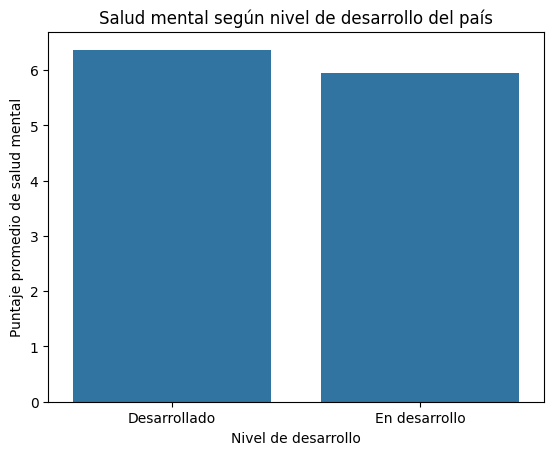

In [ ]:
# Comparamos el puntaje promedio de salud mental
# entre países desarrollados y en desarrollo.

salud_desarrollo = (
    df.groupby("Nivel_Desarrollo")["Mental_Health_Score"]
      .mean()
      .reset_index()
)

sns.barplot(
    data=salud_desarrollo,
    x="Nivel_Desarrollo",
    y="Mental_Health_Score"
)

plt.title("Salud mental según nivel de desarrollo del país")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Puntaje promedio de salud mental")
plt.show()

**Interpretación:**  
Al comparar el puntaje promedio de salud mental según el nivel de desarrollo del país, se observa que los estudiantes de **países en desarrollo presentan un puntaje promedio menor** que aquellos pertenecientes a países desarrollados.

Dado que en este análisis un valor más alto de `Mental_Health_Score` representa un mejor estado de salud mental, este resultado sugiere que los estudiantes de países en desarrollo presentan un indicador de bienestar mental relativamente menos favorable dentro de la muestra. Sin embargo, esta diferencia representa una asociación descriptiva y no permite establecer una relación causal.

### 2.5.5 | Impacto académico percibido según grupo de edad

Para analizar el impacto sobre el rendimiento académico, se comparan las **proporciones de estudiantes que indican si las redes sociales afectan o no su desempeño académico**.

Se utiliza un gráfico de barras apiladas debido a que `Affects_Academic_Performance` es una variable categórica. De esta manera, es posible comparar el porcentaje de respuestas dentro de cada grupo de edad, independientemente de las diferencias en el tamaño de los grupos.

---

In [ ]:
# Calculamos qué porcentaje de cada grupo de edad
# responde cada categoría de impacto académico.

impacto_edad = pd.crosstab(
    df["Grupo_Edad"],
    df["Affects_Academic_Performance"],
    normalize="index"
) * 100

impacto_edad

Affects_Academic_Performance,No,Yes
Grupo_Edad,,
18-20,33.089133,66.910867
21-22,36.731844,63.268156
23-24,52.403846,47.596154


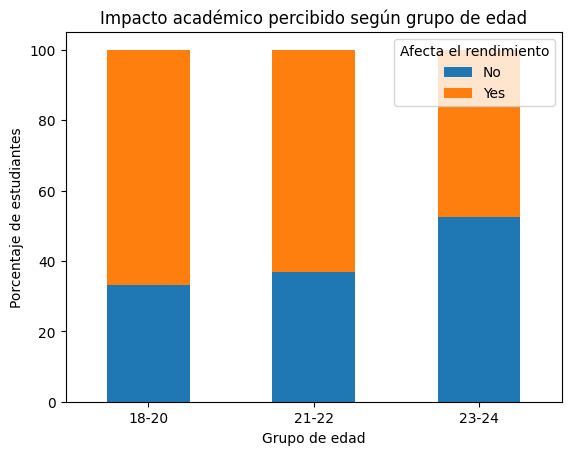

In [ ]:
# Creamos un gráfico de barras apiladas
# para visualizar la proporción de respuestas.

impacto_edad.plot(
    kind="bar",
    stacked=True
)

plt.title("Impacto académico percibido según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Porcentaje de estudiantes")
plt.legend(title="Afecta el rendimiento")
plt.xticks(rotation=0)
plt.show()

### 2.5.6 | Distribución del uso diario según grupo de edad

Finalmente, se utiliza un diagrama de caja (*boxplot*) para analizar la distribución de las horas diarias de uso de redes sociales en cada grupo etario.

A diferencia del gráfico de promedios, esta visualización permite observar no solo la tendencia central, sino también la **dispersión de los datos y la presencia de posibles valores extremos**, proporcionando una visión más completa de las diferencias entre los grupos.

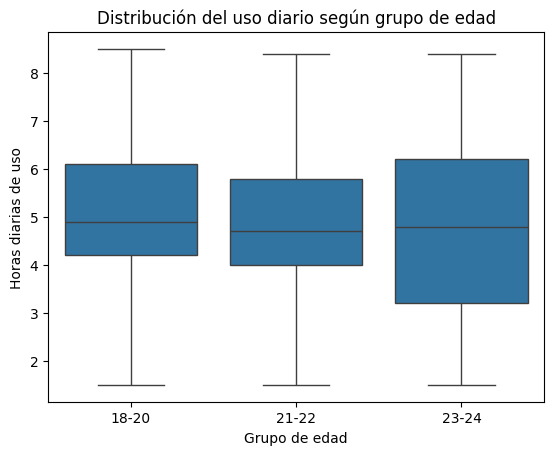

In [ ]:
# Mostramos la distribución completa de las horas de uso
# dentro de cada grupo de edad.

sns.boxplot(
    data=df,
    x="Grupo_Edad",
    y="Avg_Daily_Usage_Hours"
)

plt.title("Distribución del uso diario según grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Horas diarias de uso")
plt.show()

### 2.5.7 | Distribución de las horas de sueño según nivel de desarrollo

Para ampliar la comparación entre estudiantes de países desarrollados y en desarrollo, se analiza la distribución de las **horas de sueño por noche**.

Se utiliza un diagrama de caja (*boxplot*) porque permite comparar la mediana, la dispersión y la presencia de posibles valores extremos entre ambos grupos. De esta manera, se puede observar si existen diferencias en los patrones de descanso según el nivel de desarrollo del país.

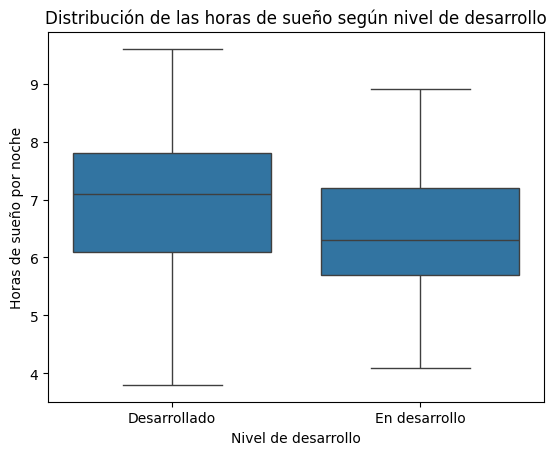

In [22]:
# Comparamos la distribución de las horas de sueño
# entre estudiantes de países desarrollados y en desarrollo.

sns.boxplot(
    data=df,
    x="Nivel_Desarrollo",
    y="Sleep_Hours_Per_Night"
)

plt.title("Distribución de las horas de sueño según nivel de desarrollo")
plt.xlabel("Nivel de desarrollo")
plt.ylabel("Horas de sueño por noche")
plt.show()

**Interpretación:**  
El boxplot permite comparar la distribución de las horas de sueño entre estudiantes de países desarrollados y en desarrollo. Las diferencias en la posición de las medianas permiten identificar qué grupo presenta, en términos generales, una menor cantidad de horas de descanso, mientras que el tamaño de las cajas permite observar la variabilidad existente dentro de cada grupo.

## 2.6 | Conclusión (nivel de desarrollo del país)

A partir del análisis realizado, se observan diferencias entre los estudiantes pertenecientes a **países desarrollados** y aquellos de **países en desarrollo** en varios de los indicadores vinculados al uso e impacto de las redes sociales.

En términos generales, los estudiantes de países en desarrollo presentan **un mayor promedio de horas diarias de uso de redes sociales** y, al mismo tiempo, **un puntaje promedio de salud mental más bajo**. Considerando que en este trabajo un valor mayor de `Mental_Health_Score` representa un mejor estado de salud mental, estos resultados muestran un perfil relativamente menos favorable para este grupo dentro de la muestra analizada.

Las visualizaciones realizadas permiten reforzar esta diferencia, ya que muestran de manera clara cómo se distribuyen los principales indicadores entre ambos grupos de países.

Sin embargo, estos resultados deben interpretarse con cautela. La clasificación entre países desarrollados y en desarrollo se construyó a partir del nivel de ingreso definido por el Banco Mundial, lo cual simplifica un concepto multidimensional como el desarrollo. Además, el análisis es de carácter descriptivo, por lo que permite identificar asociaciones y diferencias entre grupos, pero no establecer que el nivel de desarrollo del país sea la causa directa de los resultados observados.

En conclusión, dentro de este dataset se identifica una asociación entre el nivel de desarrollo del país y algunos indicadores relacionados con el uso de redes sociales y el bienestar de los estudiantes, siendo los resultados menos favorables, en promedio, para quienes pertenecen a países en desarrollo.

### Síntesis de la Parte 2

- **Edad:** el grupo de **18 a 20 años** presenta los indicadores más desfavorables (mayor uso diario, menor puntaje de salud mental y mayor proporción de estudiantes que declaran que las redes afectan su rendimiento académico), mientras que el grupo de 23 a 24 años muestra los resultados relativamente más favorables, aunque con menos observaciones.
- **Nivel de desarrollo:** los estudiantes de **países en desarrollo** usan más horas las redes, duermen menos, tienen un puntaje de salud mental más bajo y declaran en mayor proporción que las redes afectan su rendimiento académico.
- En ambos casos se trata de asociaciones descriptivas dentro de la muestra, no de relaciones causales.

---

# Parte 3 | Uso de redes sociales, sueño y rendimiento académico

Esta parte analiza dos preguntas relacionadas:

- ¿Hay un impacto en lo académico dado el uso de redes sociales?
- ¿Hay un impacto en la calidad de sueño?

El análisis vuelve a cargar el dataset original y trabaja con todas sus filas. Se utilizan diagramas de dispersión con recta de tendencia y diagramas de caja para comparar a los estudiantes que declaran que las redes afectan su rendimiento académico con los que no.

In [122]:
from os import rename

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

data_url = 'http://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/Facu/data/raw/dataset_final'
df = pd.read_csv(data_url)
df.head()


#Preguntas 2 y 4
#2: Hay un impacto en lo academico dado el uso de redes sociales?
#4: Hay un impacto en la calidad de sueño?

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


## 3.1 | Como repercute el uso de redes sociales en el sueño

Se cree comunmente que el uso de pantallas durante periodos prolongados de tiempo repercute negativamente en el sueño.

Se puede observar una clara relación entre el incremento de tiempo de uso de redes sociales y la reduccion de las horas de sueño.

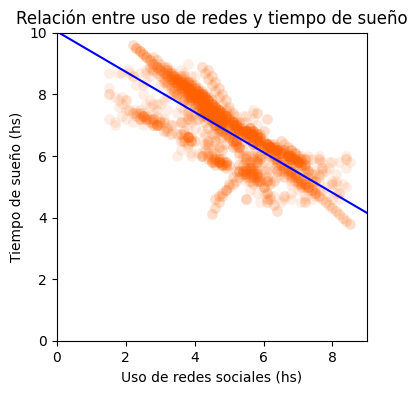

In [123]:
#Sera que el impacto se produce por la falta de sueño?

plt.figure(figsize=(4,4))

plt.scatter(
    df['Avg_Daily_Usage_Hours'],
    df['Sleep_Hours_Per_Night'],
    s=60, c='#FE6100', alpha=0.1, lw=0,)

m,b = np.polyfit(df["Avg_Daily_Usage_Hours"], df['Sleep_Hours_Per_Night'], 1)
def f(x):
  return (x * m) + b

recorrido = np.linspace(0,9,100)
plt.plot(recorrido, f(recorrido), color="blue")

plt.xlim((0,9))
plt.ylim((0,10))
plt.xlabel("Uso de redes sociales (hs)")
plt.ylabel("Tiempo de sueño (hs)")
plt.title("Relación entre uso de redes y tiempo de sueño")

plt.show()

## 3.2 | ¿Como afecta esto al rendimiento academico?

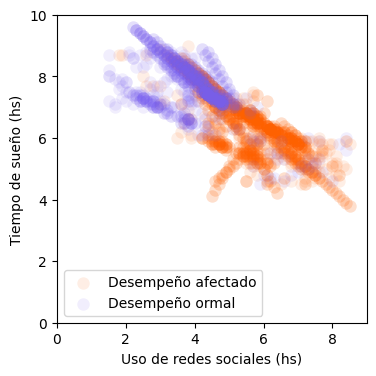

In [55]:
#Sera que el impacto se produce por la falta de sueño?

plt.figure(figsize=(4,4))

afectados = df.loc[df['Affects_Academic_Performance']=="Yes"]
no_afectados = df.loc[df['Affects_Academic_Performance']=="No"]

plt.scatter(
    afectados['Avg_Daily_Usage_Hours'],
    afectados['Sleep_Hours_Per_Night'],
    s=80, c='#FE6100', alpha=0.1, lw=0, label='Desempeño afectado')
plt.scatter(
    no_afectados['Avg_Daily_Usage_Hours'],
    no_afectados['Sleep_Hours_Per_Night'],
    s=80, c='#785EF0', alpha=0.1, lw=0, label="Desempeño ormal")

plt.xlim((0,9))
plt.ylim((0,10))
plt.xlabel("Uso de redes sociales (hs)")
plt.ylabel("Tiempo de sueño (hs)")

plt.legend()
plt.show()



(3.0, 10.0)

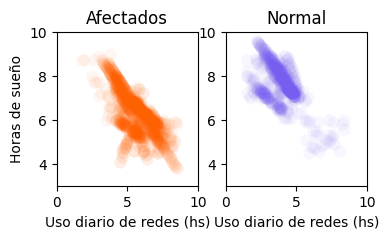

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(4, 2))

ax[0].scatter(
    afectados['Avg_Daily_Usage_Hours'],
    afectados['Sleep_Hours_Per_Night'],
    s=80, c='#FE6100', alpha=0.05, lw=0, label='Mal desempeño')

ax[0].set_title("Afectados")
ax[0].set_xlabel("Uso diario de redes (hs)")
ax[0].set_xlim((0,10))
ax[0].set_ylabel("Horas de sueño")
ax[0].set_ylim((3,10))

ax[1].scatter(
    no_afectados['Avg_Daily_Usage_Hours'],
    no_afectados['Sleep_Hours_Per_Night'],
    s=80, c='#785EF0', alpha=0.05, lw=0, label="Normal")

ax[1].set_title("Normal")
ax[1].set_xlabel("Uso diario de redes (hs)")
ax[1].set_xlim((0,10))
ax[1].set_ylim((3,10))

Se puede observar que aquellos cuyo desempeño academico se vio perjudicado tienen menos horas de sueño, y mayor uso de redes sociales.

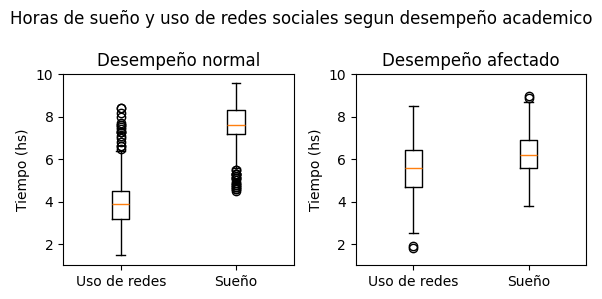

In [121]:
fig, ax = plt.subplots(1,2 ,figsize=(6, 3))

ax[0].boxplot(
    [
        no_afectados["Avg_Daily_Usage_Hours"],
        no_afectados["Sleep_Hours_Per_Night"]
    ],
    tick_labels=["Uso de redes", "Sueño"]
)
ax[1].boxplot(
    [
        afectados["Avg_Daily_Usage_Hours"],
        afectados["Sleep_Hours_Per_Night"]
    ],
    tick_labels=["Uso de redes", "Sueño"]
)

ax[0].set_title("Desempeño normal")
ax[0].set_ylabel("Tiempo (hs)")
ax[0].set_ylim((1, 10))

ax[1].set_ylabel("Tiempo (hs)")
ax[1].set_title("Desempeño afectado")
ax[1].set_ylim((1, 10))
fig.suptitle("Horas de sueño y uso de redes sociales segun desempeño academico")

plt.tight_layout()
plt.show()

---

# Parte 4 | Horas dedicadas a cada red social según la edad y relación con la salud mental

Esta parte vuelve a cargar el dataset y construye un `df_final` (sin `Relationship_Status`) al que se le agrega la variable `Continent`. Luego se filtran las plataformas de interés (`df_filtrado`: Instagram, YouTube, Facebook, TikTok, Twitter y WhatsApp) para comparar las horas de uso por red social, por edad, y finalmente su relación con la salud mental.

## 4.1 | Carga y exploración inicial

Se importan las librerías necesarias para el análisis y procesamiento de datos. Posteriormente, se realiza la carga del conjunto de datos (*dataset*) y una primera exploración de su estructura.

Como parte de esta etapa inicial, se identifican y analizan los valores nulos presentes en las distintas variables, con el objetivo de evaluar la calidad de los datos y determinar si es necesario realizar un tratamiento de los mismos antes de continuar con el análisis.





In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
url = "https://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/Facu/data/raw/dataset_final"
df = pd.read_csv(url)

In [10]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


In [11]:
print("Nulos por columna:")
print(df.isnull().sum())                                 # isnull() marca cada celda vacía; sum() las cuenta por columna
print("\nFilas duplicadas:", df.duplicated().sum())

Nulos por columna:
Student_ID                         0
Age                                0
Gender                             0
Academic_Level                     0
Country                            0
Avg_Daily_Usage_Hours              0
Most_Used_Platform                 0
Affects_Academic_Performance       0
Sleep_Hours_Per_Night              0
Mental_Health_Score                0
Relationship_Status             1038
dtype: int64

Filas duplicadas: 0


Tenemos la columa 'Relationship_Status' que contiene muchos valores nulos. Se eliminan para obtener el dataframe final.

In [12]:
# Eliminar la columna Relationship_Status del dataset filtrado
df_final = df.drop(columns=['Relationship_Status'])

# Verificar las columnas resultantes
print("Columnas en el nuevo dataset:")
print(df_final.columns.tolist())

# Mostrar una vista previa
df_final.head()

Columnas en el nuevo dataset:
['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country', 'Avg_Daily_Usage_Hours', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Mental_Health_Score']


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0


Veamos cuántos valores de 'Country' tiene nuestro dataset

In [13]:
paises_unicos = df_final['Country'].unique()
print(f"Número de países únicos: {len(paises_unicos)}")
print(paises_unicos)

Número de países únicos: 110
['Canada' 'USA' 'India' 'Australia' 'UK' 'Germany' 'Bangladesh' 'Brazil'
 'Japan' 'South Korea' 'France' 'Spain' 'Italy' 'Mexico' 'Russia' 'China'
 'Sweden' 'Norway' 'Denmark' 'Netherlands' 'Belgium' 'Switzerland'
 'Austria' 'Portugal' 'Greece' 'Ireland' 'New Zealand' 'Singapore'
 'Malaysia' 'Thailand' 'Vietnam' 'Philippines' 'Indonesia' 'Taiwan'
 'Hong Kong' 'Turkey' 'Israel' 'UAE' 'Egypt' 'Morocco' 'South Africa'
 'Nigeria' 'Kenya' 'Ghana' 'Argentina' 'Chile' 'Colombia' 'Peru'
 'Venezuela' 'Ecuador' 'Uruguay' 'Paraguay' 'Bolivia' 'Costa Rica'
 'Panama' 'Jamaica' 'Trinidad' 'Bahamas' 'Iceland' 'Finland' 'Poland'
 'Romania' 'Hungary' 'Czech Republic' 'Slovakia' 'Croatia' 'Serbia'
 'Slovenia' 'Bulgaria' 'Estonia' 'Latvia' 'Lithuania' 'Ukraine' 'Moldova'
 'Belarus' 'Kazakhstan' 'Uzbekistan' 'Kyrgyzstan' 'Tajikistan' 'Armenia'
 'Georgia' 'Azerbaijan' 'Cyprus' 'Malta' 'Luxembourg' 'Monaco' 'Andorra'
 'San Marino' 'Vatican City' 'Liechtenstein' 'Montenegro' 'Alb

Como son muchos valores, los agrupamos por continente.

In [14]:
# Diccionario: país -> continente
continentes = {
    # América del Norte
    'Canada': 'América del Norte',
    'USA': 'América del Norte',
    'Mexico': 'América del Norte',
    'Costa Rica': 'América del Norte',
    'Panama': 'América del Norte',
    'Jamaica': 'América del Norte',
    'Trinidad': 'América del Norte',
    'Bahamas': 'América del Norte',

    # América del Sur
    'Brazil': 'América del Sur',
    'Argentina': 'América del Sur',
    'Chile': 'América del Sur',
    'Colombia': 'América del Sur',
    'Peru': 'América del Sur',
    'Venezuela': 'América del Sur',
    'Ecuador': 'América del Sur',
    'Uruguay': 'América del Sur',
    'Paraguay': 'América del Sur',
    'Bolivia': 'América del Sur',

    # Europa
    'UK': 'Europa',
    'Germany': 'Europa',
    'France': 'Europa',
    'Spain': 'Europa',
    'Italy': 'Europa',
    'Sweden': 'Europa',
    'Norway': 'Europa',
    'Denmark': 'Europa',
    'Netherlands': 'Europa',
    'Belgium': 'Europa',
    'Switzerland': 'Europa',
    'Austria': 'Europa',
    'Portugal': 'Europa',
    'Greece': 'Europa',
    'Ireland': 'Europa',
    'Iceland': 'Europa',
    'Finland': 'Europa',
    'Poland': 'Europa',
    'Romania': 'Europa',
    'Hungary': 'Europa',
    'Czech Republic': 'Europa',
    'Slovakia': 'Europa',
    'Croatia': 'Europa',
    'Serbia': 'Europa',
    'Slovenia': 'Europa',
    'Bulgaria': 'Europa',
    'Estonia': 'Europa',
    'Latvia': 'Europa',
    'Lithuania': 'Europa',
    'Ukraine': 'Europa',
    'Moldova': 'Europa',
    'Belarus': 'Europa',
    'Cyprus': 'Europa',
    'Malta': 'Europa',
    'Luxembourg': 'Europa',
    'Monaco': 'Europa',
    'Andorra': 'Europa',
    'San Marino': 'Europa',
    'Vatican City': 'Europa',
    'Liechtenstein': 'Europa',
    'Montenegro': 'Europa',
    'Albania': 'Europa',
    'North Macedonia': 'Europa',
    'Kosovo': 'Europa',
    'Bosnia': 'Europa',

    # Asia
    'India': 'Asia',
    'Bangladesh': 'Asia',
    'Japan': 'Asia',
    'South Korea': 'Asia',
    'China': 'Asia',
    'Singapore': 'Asia',
    'Malaysia': 'Asia',
    'Thailand': 'Asia',
    'Vietnam': 'Asia',
    'Philippines': 'Asia',
    'Indonesia': 'Asia',
    'Taiwan': 'Asia',
    'Hong Kong': 'Asia',
    'Turkey': 'Asia',
    'Israel': 'Asia',
    'UAE': 'Asia',
    'Kazakhstan': 'Asia',
    'Uzbekistan': 'Asia',
    'Kyrgyzstan': 'Asia',
    'Tajikistan': 'Asia',
    'Armenia': 'Asia',
    'Georgia': 'Asia',
    'Azerbaijan': 'Asia',
    'Qatar': 'Asia',
    'Kuwait': 'Asia',
    'Bahrain': 'Asia',
    'Oman': 'Asia',
    'Jordan': 'Asia',
    'Lebanon': 'Asia',
    'Iraq': 'Asia',
    'Yemen': 'Asia',
    'Syria': 'Asia',
    'Afghanistan': 'Asia',
    'Pakistan': 'Asia',
    'Nepal': 'Asia',
    'Bhutan': 'Asia',
    'Sri Lanka': 'Asia',
    'Maldives': 'Asia',

    # África
    'Egypt': 'África',
    'Morocco': 'África',
    'South Africa': 'África',
    'Nigeria': 'África',
    'Kenya': 'África',
    'Ghana': 'África',

    # Oceanía
    'Australia': 'Oceanía',
    'New Zealand': 'Oceanía',

    # Rusia: país transcontinental
    'Russia': 'Europa/Asia',
}

# Crear la nueva columna
df_final['Continent'] = df['Country'].map(continentes)

# Verificar si hay países sin correspondencia
print(df_final[df_final['Continent'].isna()]['Country'].unique())

# Ver una muestra del resultado
print(df_final[['Country', 'Continent']].head())


[]
     Country          Continent
0     Canada  América del Norte
1        USA  América del Norte
2      India               Asia
3        USA  América del Norte
4  Australia            Oceanía


La lista vacía nos asegura que no quedaron valores nulos en la variable 'Continente'

In [15]:
df_final.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Continent
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,América del Norte
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,América del Norte
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,Asia
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,América del Norte
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,Oceanía


Corroboramos que los continentes que nos quedan sean únicos

In [16]:
continentes_unicos = df_final['Continent'].unique()
print(f"Número de países únicos: {len(continentes_unicos)}")
print(continentes_unicos)

Número de países únicos: 7
['América del Norte' 'Asia' 'Oceanía' 'Europa' 'América del Sur'
 'Europa/Asia' 'África']


## 4.2 | ¿Cuantas horas le dedican a cada red social según edad?

Lo primero es ver con cuáles redes sociales contamos



In [17]:
plataformas_unicas = df_final['Most_Used_Platform'].unique()
print(f"Número de plataformas únicas: {len(plataformas_unicas)}")
print(plataformas_unicas)

Número de plataformas únicas: 12
['Instagram' 'YouTube' 'Facebook' 'TikTok' 'LinkedIn' 'Twitter' 'Snapchat'
 'LINE' 'KakaoTalk' 'VKontakte' 'WhatsApp' 'WeChat']


Hay muchas redes sociales que desconocemos y otras que no son relevantes para nuestro análisis, por lo que nos quedamos con Instagram, Youtube, Facebook, Tiktok, Twitter y WhatsApp

In [18]:
# Definir la lista de plataformas deseadas
plataformas_interes = ['Instagram', 'YouTube', 'Facebook', 'TikTok', 'Twitter','WhatsApp']

# Filtrar el DataFrame
df_filtrado = df_final[df_final['Most_Used_Platform'].isin(plataformas_interes)]

# Mostrar información del nuevo dataset filtrado
print(f"Cantidad de filas antes del filtro: {len(df_final)}")
print(f"Cantidad de filas después del filtro: {len(df_filtrado)}")
print("\nPlataformas que quedaron en el dataset:")
print(df_filtrado['Most_Used_Platform'].unique())

# Mostrar las primeras filas
df_filtrado.head()

Cantidad de filas antes del filtro: 1743
Cantidad de filas después del filtro: 1481

Plataformas que quedaron en el dataset:
['Instagram' 'YouTube' 'Facebook' 'TikTok' 'Twitter' 'WhatsApp']


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Continent
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,América del Norte
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,América del Norte
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,Asia
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,América del Norte
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,Oceanía


Ahora estamos listos para trabajar con nuestros datos. Lo primero es agrupar con group_by por la variable 'Most_Used_Platform' antes de calcular el promedio de uso por plataforma.

In [19]:
promedio_uso = df_filtrado.groupby('Most_Used_Platform')['Avg_Daily_Usage_Hours'].mean().reset_index()
promedio_uso.columns = ['Plataforma', 'Promedio Horas de Uso']
promedio_uso = promedio_uso.sort_values(by='Promedio Horas de Uso', ascending=False)

print("--- Promedio de Horas de Uso Diario por Plataforma ---")
print(promedio_uso.to_string(index=False))
print("\n")

--- Promedio de Horas de Uso Diario por Plataforma ---
Plataforma  Promedio Horas de Uso
  WhatsApp               6.475926
    TikTok               5.367714
   Twitter               4.887379
 Instagram               4.874182
   YouTube               4.798667
  Facebook               4.694237




Esto nos indica que WhatsApp es la red social que mas horas de uso promedia por día en los estudiantes, y Facebook es la que menos horas promedia. Le sigue TikTok con un promedio de 5,37. Las otras redes sociales no varían mucho en el promedio de tiempo de uso diario. Ahora veamos como se distribuye el tiempo diario promedio de uso para cada red social.

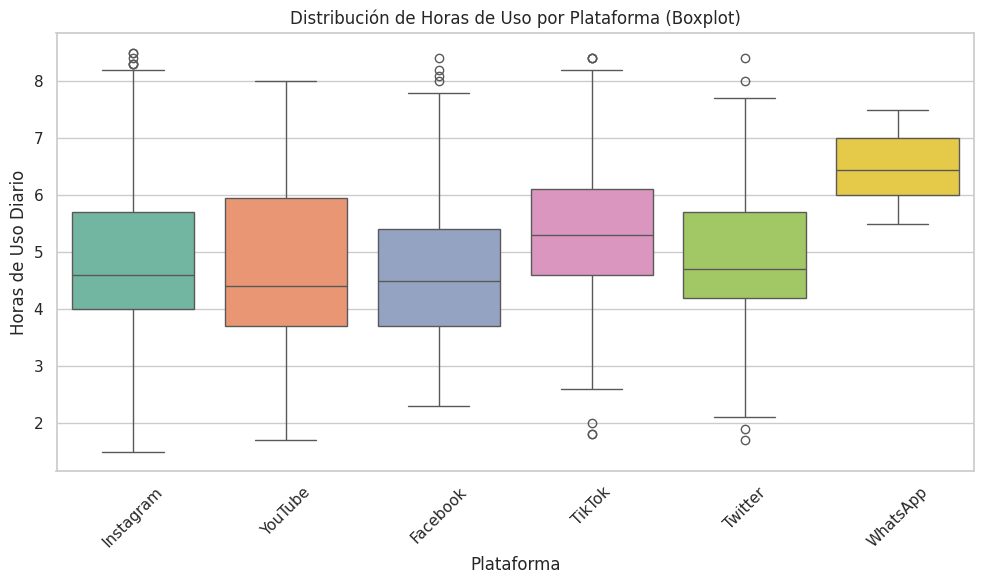

In [20]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

#Boxplot: Distribución de horas de uso diario por plataforma (usando df_final)
sns.boxplot(
    data=df_filtrado,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Set2',
    legend=False
)
plt.title('Distribución de Horas de Uso por Plataforma (Boxplot)')
plt.xlabel('Plataforma')
plt.ylabel('Horas de Uso Diario')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Esto nos muestra solo la distribución de los datos para cada red social. Pero mejor veamos si hay suficientes observaciones para cada una. Esto nos daría idea de si nuestra muestra es lo suficientemente representativa.

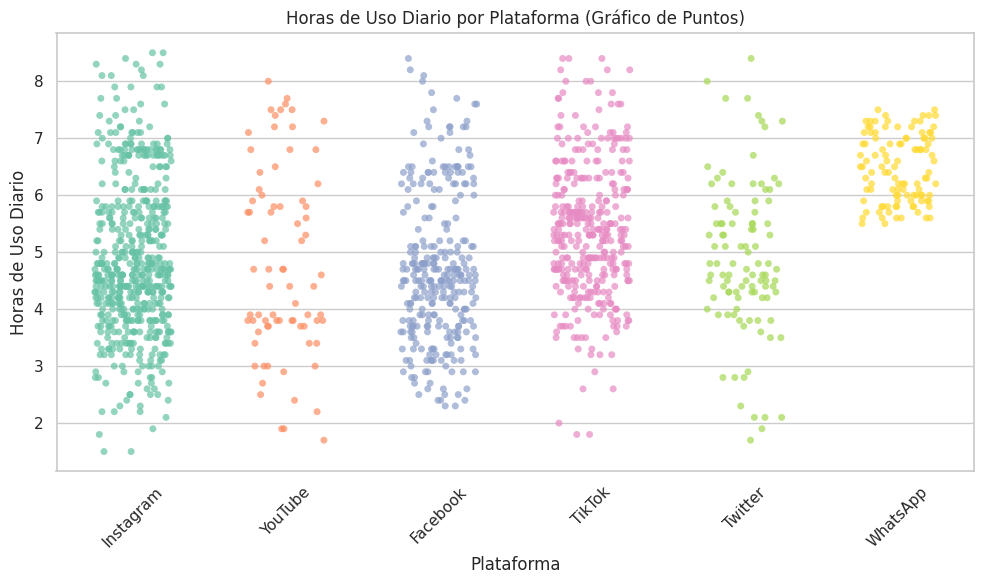

In [21]:
# Configuración de estilo
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Gráfico de puntos agrupado por plataforma
sns.stripplot(
    data=df_filtrado,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Set2',
    jitter=0.25,
    size=5,
    alpha=0.7,
    legend=False
)

plt.title('Horas de Uso Diario por Plataforma (Gráfico de Puntos)')
plt.xlabel('Plataforma')
plt.ylabel('Horas de Uso Diario')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Como vemos, YouTube y Twitter no tienen tantas observaciones como las otras redes sociales. Esto puede indicar la existencia de un sesgo ya que no son tan representativas como las otras redes sociales.





Ahora veamos que pasa si combinamos ámbos gráficos.

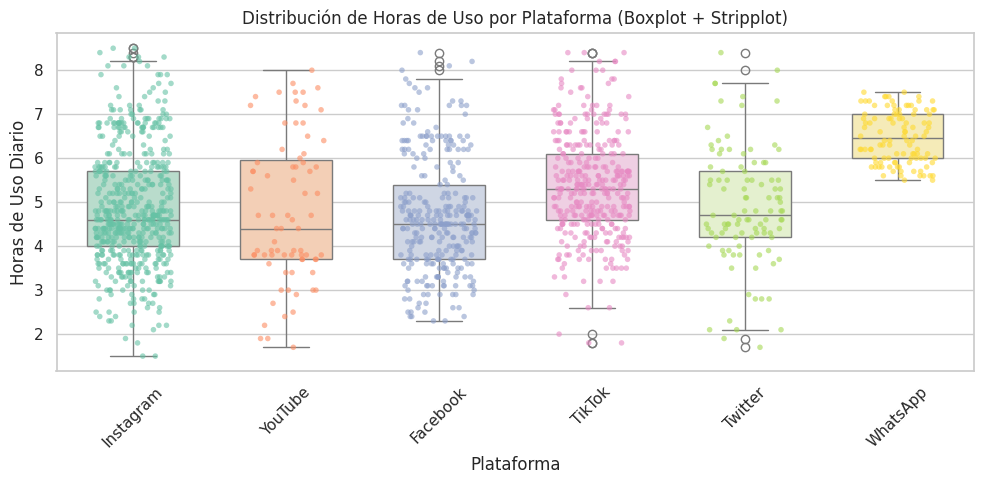

In [22]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# 1. Crear el Boxplot base de fondo
sns.boxplot(
    data=df_filtrado,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Pastel2',
    legend=False,
    width=0.6
)

# 2. Superponer el Scatterplot (Stripplot) de los puntos individuales
sns.stripplot(
    data=df_filtrado,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Set2',
    jitter=0.25,
    size=4,
    alpha=0.6,
    legend=False
)

plt.title('Distribución de Horas de Uso por Plataforma (Boxplot + Stripplot)')
plt.xlabel('Plataforma')
plt.ylabel('Horas de Uso Diario')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Con esto podemos ver bien la dispersión para cada uno de los datos.

### Observaciones

Vemos que la red social con mayor dispersión es Instagram. Con una mediana ligeramente mayor a la de Facebook, la cantidad de muestras para esta red social nos indica que tiene una gran representatividad para los estudiantes. En contraste con YouTube que quizás no cuente con las observaciones suficientes para mostrar la representatividad que otras redes sociales. Similar a Twitter que tiene una mediana ligeramente mayor entre las redes sociales anteriormente mencionadas.

WhatsApp es la red social con menor dispersión de todas. Tiene una cantidad significativa de observaciones por lo que muestra que los estudiantes que usan WhatsApp mas que otras redes tienden a usarlo en promedio una mayor cantidad de horas. Esto nos indica que WhasApp tiene un gran potencial adictivo en los estudiantes. Sin embargo no se debe dejar de tener en cuenta que es la red de comunicación principal en el mundo. Por lo que se uso prolongado no podría indicar en todos los casos adicción como tal.

La segunda red social con mayor potencial adictivo es TikTok, teniendo la segunda mediana mas grande de cada red social.

## 4.3 | Ahora, el mismo análisis, pero por edad

In [23]:
# Crear una tabla dinámica (pivot table) para ver el promedio de uso diario por cada edad exacta y plataforma
cuadro_por_edad = df_filtrado.pivot_table(
    values='Avg_Daily_Usage_Hours',
    index='Age',
    columns='Most_Used_Platform',
    aggfunc='mean'
).round(2)

# Llenar posibles valores vacíos (en caso de que no haya registro para una combinación de edad/plataforma) con '-' para mejor lectura
cuadro_por_edad_formateado = cuadro_por_edad.fillna('-')

print("--- Promedio de Horas de Uso Diario por Edad Exacta y Plataforma ---")
display(cuadro_por_edad_formateado)

--- Promedio de Horas de Uso Diario por Edad Exacta y Plataforma ---


Most_Used_Platform,Facebook,Instagram,TikTok,Twitter,WhatsApp,YouTube
Age,,,,,,
18,4.87,5.69,5.74,4.26,-,4.22
19,5.40,5.09,5.49,4.78,6.5,5.50
20,4.92,4.60,5.43,5.09,7.1,4.57
21,4.49,4.72,5.55,4.82,6.45,4.57
22,4.39,4.69,4.87,4.88,6.4,5.17
23,5.27,5.05,5.02,4.88,-,4.83
24,5.29,5.91,5.78,5.14,-,4.98


Lo mas llamativo es que, para WhatsApp, no encontramos observaciones para las edades 18, 23 y 24. Es apropiado ver que cantidad de observaciones hay para cada red social y cada edad para darnos una idea de la representatividad.

In [24]:
# Adicionalmente, creamos un cuadro con la cantidad de estudiantes (conteo) por edad y plataforma para dar contexto de los datos, incluyendo totales
cuadro_conteo_edad = df_filtrado.pivot_table(
    values='Avg_Daily_Usage_Hours',
    index='Age',
    columns='Most_Used_Platform',
    aggfunc='count',
    margins=True,
    margins_name='Total'
).fillna(0).astype(int)

print("--- Cantidad de Alumnos por Edad Exacta y Plataforma (con Totales) ---")
display(cuadro_conteo_edad)

--- Cantidad de Alumnos por Edad Exacta y Plataforma (con Totales) ---


Most_Used_Platform,Facebook,Instagram,TikTok,Twitter,WhatsApp,YouTube,Total
Age,,,,,,,
18,6,15,14,7,0,8,50
19,24,182,84,17,16,8,331
20,47,134,113,14,6,13,327
21,82,134,47,12,44,20,339
22,103,47,65,17,42,14,288
23,15,28,13,18,0,6,80
24,18,10,14,18,0,6,66
Total,295,550,350,103,108,75,1481


Ahora sabemos que, para cualquier conclusión que saquemos, nuestra muestra no va a tener la misma representatividad para Youtube, Twitter, WhastsApp y las edades de 18, 23 y 24. Puede ser que a la edad de 18 años no despierte interés el uso de WhatsApp en los estudiantes y que de los 19 a los 22 la vida social de los estudiantes sea mas activa, lo que justifica su actividad en WhatsApp.

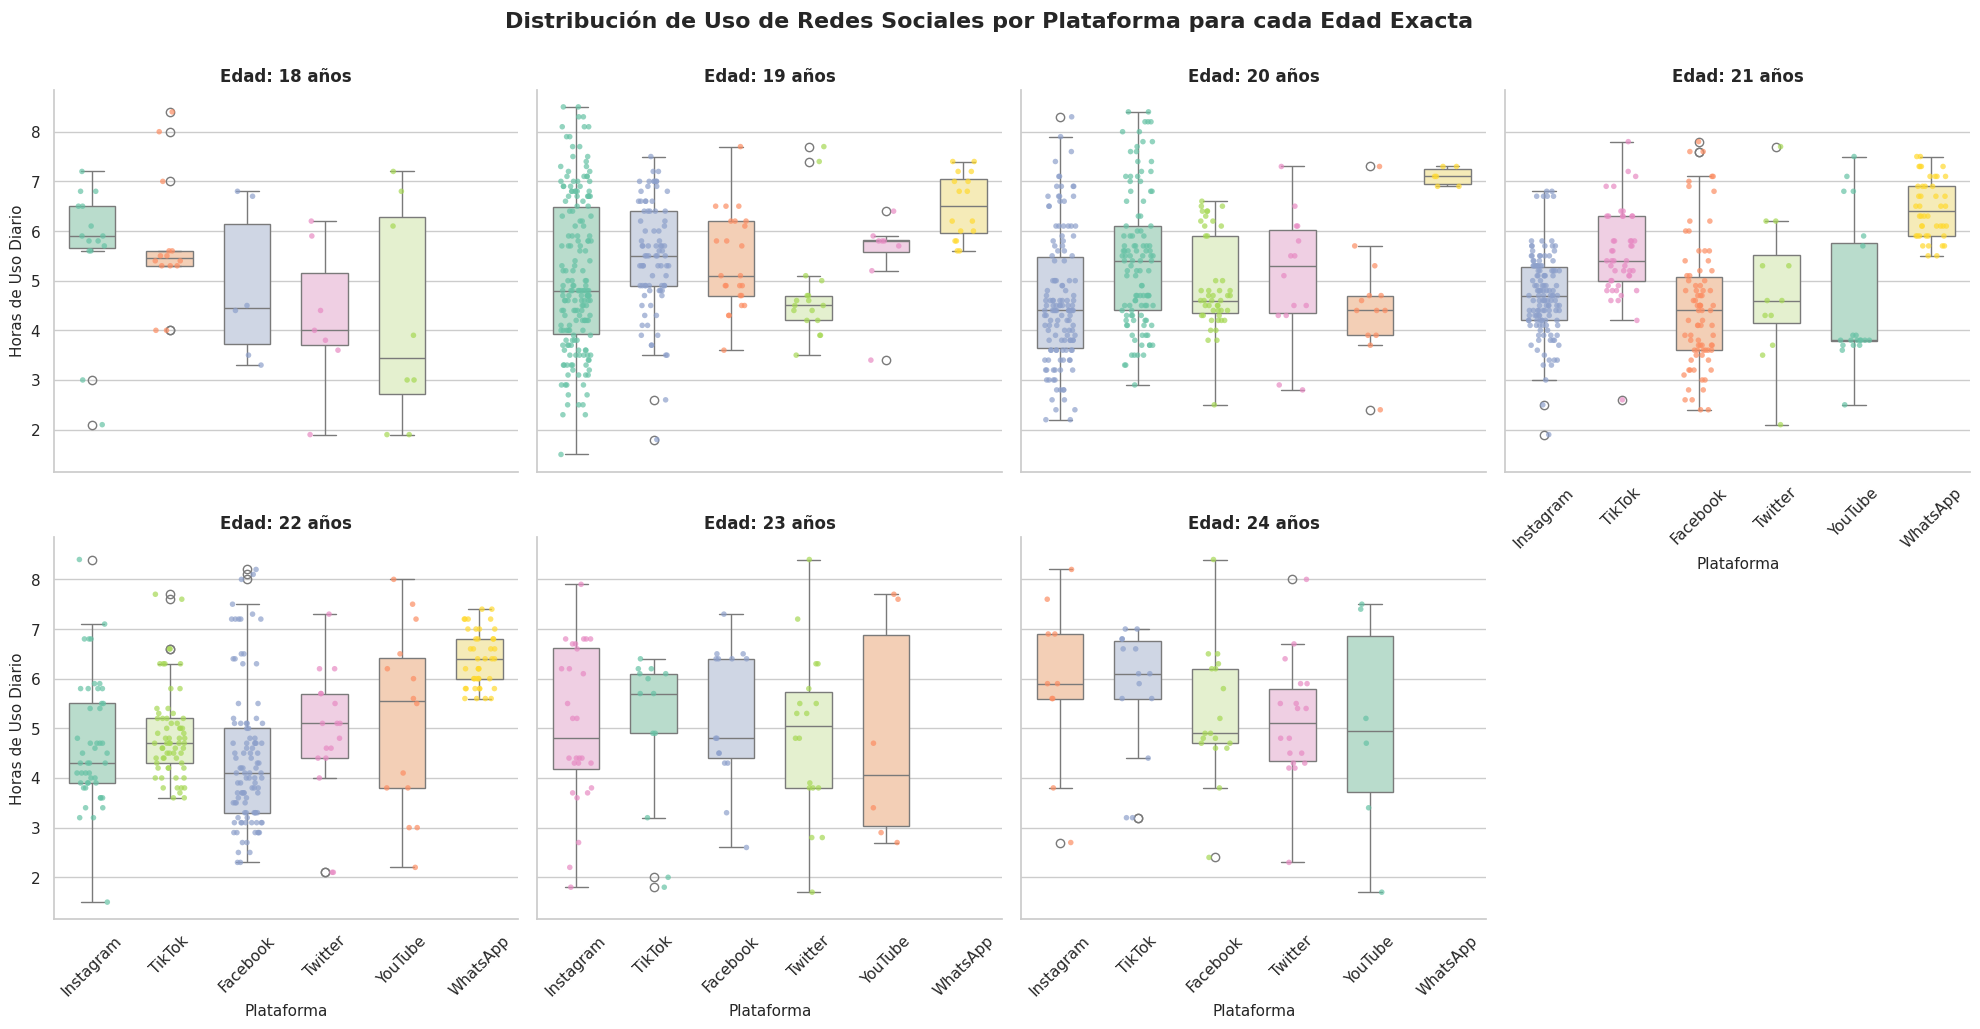

In [25]:
sns.set_theme(style="whitegrid")

# Crear un FacetGrid con un panel para cada edad exacta
g_edades = sns.FacetGrid(
    df_filtrado,
    col="Age",
    col_wrap=4,
    height=5,
    aspect=1.0,
    sharey=True
)

# 1. Dibujar el Boxplot para cada edad en su respectivo panel
g_edades.map_dataframe(
    sns.boxplot,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Pastel2',
    legend=False,
    width=0.6
)

# 2. Superponer el Stripplot (scatterplot) con los puntos individuales en cada panel
g_edades.map_dataframe(
    sns.stripplot,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Set2',
    jitter=0.2,
    size=4,
    alpha=0.7,
    legend=False
)

# Ajustar los títulos de cada panel, etiquetas y rotación de plataformas
g_edades.set_titles("Edad: {col_name} años", size=12, weight='bold')
g_edades.set_axis_labels("Plataforma", "Horas de Uso Diario", size=11)

for ax in g_edades.axes.flat:
    ax.tick_params(axis='x', labelrotation=45)

plt.subplots_adjust(top=0.9)
g_edades.fig.suptitle('Distribución de Uso de Redes Sociales por Plataforma para cada Edad Exacta', size=16, weight='bold')

plt.show()

### Observaciones

- Vemos que Instagram empieza a despertar un interés rápidamente a los 18 años, con una alta mediana en la cantidad de horas de uso. Se incrementa la cantidad de usuarios por edad hasta los 21. A los 22 años vemos que empieza a disminuir el uso diario promedio de Instagram por edad.
- TikTok tiene un gran potencial adictivo, con medianas que, en su mayoría, no bajan del promedio de 5 horas de uso (a excepción de la edad de 22 años).
- A pesar de la gran cantidad de usuarios que usan Facebook mas que otras redes sociales, tienen algo mas de control sobre el uso promedio diario. Esto se evidencia de los 20 a los 22, cuyas medianas no superan las 5 horas diarias pese al gran número de observaciones.
- YouTube no promedia una gran adicción para todas las edades. Se vió previamente en la poca cantidad de observaciones y se ve en la irregularidad de los gráficos para cada edad. En algunos gráficos tenemos una gran dispersión, mientras que en otros no tenemos gran dispersión, incluso compartiendo primer cuartil y mediana en el gráfico para 21 años.
- Si bien no hay muchas observaciones para Twitter, se puede ver que a los 19 años los estudiantes empiezan a ocupar mas tiempo en twitter, siendo mas frecuente que tengan un promedio de aproximadamente 5 horas de uso diario.

## 4.4 | Horas que le dedican a cada red social según edad

In [26]:
# Calcular métricas estadísticas de uso diario agrupado por plataforma
metricas_plataformas = df_filtrado.groupby('Most_Used_Platform')['Avg_Daily_Usage_Hours'].agg(
    Count='count',
    Promedio='mean',
    Mediana='median',
    Minimo='min',
    Maximo='max',
    Desviacion_Estandar='std'
).reset_index()

# Mostrar el DataFrame resultante ordenado por el promedio de uso diario
metricas_plataformas = metricas_plataformas.sort_values(by='Promedio', ascending=False)
display(metricas_plataformas)

,Most_Used_Platform,Count,Promedio,Mediana,Minimo,Maximo,Desviacion_Estandar
4,WhatsApp,108,6.475926,6.45,5.5,7.5,0.584195
2,TikTok,350,5.367714,5.30,1.8,8.4,1.188851
3,Twitter,103,4.887379,4.70,1.7,8.4,1.342786
1,Instagram,550,4.874182,4.60,1.5,8.5,1.337829
5,YouTube,75,4.798667,4.40,1.7,8.0,1.651166
0,Facebook,295,4.694237,4.50,2.3,8.4,1.299896


WhatsApp es la red social que promedia mayor promedio de tiempo de uso entre todas las redes sociales. Teniendo en cuenta la cantidad de observaciones para cada red social, podemos afirmar que TikTok es la red social con mayor potencial adictivo dado su elevado número de observaciones y su mediana.

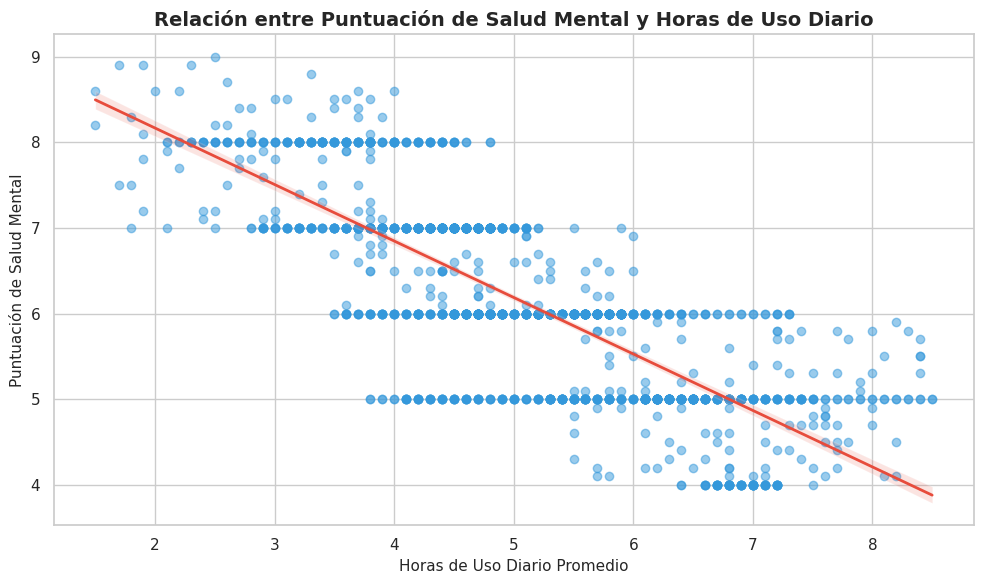

In [29]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear el gráfico de dispersión con la línea de tendencia intercambiando los ejes
sns.regplot(
    data=df_filtrado,
    x='Avg_Daily_Usage_Hours',
    y='Mental_Health_Score',
    scatter_kws={'alpha':0.5, 'color': '#3498db'},
    line_kws={'color': '#e74c3c', 'linewidth': 2}
)

# Personalizar títulos y etiquetas con el nuevo orden
plt.title('Relación entre Puntuación de Salud Mental y Horas de Uso Diario', size=14, weight='bold')
plt.xlabel('Horas de Uso Diario Promedio', size=11)
plt.ylabel('Puntuación de Salud Mental', size=11)

# Mostrar el gráfico
plt.tight_layout()
plt.show()

Se puede ver una clara tendencia de como decrece la salud mental de los estudiantes mientras mayor es el uso diario promedio. Se ajustó una recta para obsrrvar mejor esta tendencia decreciente.

---

# Parte 5 | ¿Hay redes sociales que impactan más que otras? ¿Existe una brecha de género?

Esta parte realiza su propia carga y exploración del dataset, en la que se detecta que existen **filas duplicadas** ocultas por la columna `Relationship_Status`. Por eso, a diferencia de las partes anteriores, aquí se trabaja con el dataset **sin duplicados** (1.038 estudiantes) y se crean nuevas variables (`Plataforma`, `Afecta_Rendimiento`, `Nivel_Uso`).

## 5.1 | Presentación
**¿Cual es el impacto de las redes sociales en la calidad de vida de los estudiantes?**

**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión · Trabajo práctico grupal**

Este notebook responde dos preguntas sobre el impacto de las redes sociales en estudiantes:

- ¿Hay **redes sociales** que impactan más que otras?
- ¿Existe una **brecha de género** en ese impacto?

### 🤖 Uso de IA

La herramienta de IA utilizada fue **Claude** (Anthropic), que se empleó para **ayudar y apoyar en la escritura del código en las diferentes celdas del notebook** (carga y exploración de datos, transformaciones y gráficos).

## 5.2 | Carga y exploración inicial

Importamos todas las librerías que vamos a utiliza: `pandas` para las tablas, `numpy` para cuentas, `matplotlib` y `seaborn` para los gráficos.

In [ ]:
import numpy as np                       # números y cuentas
import pandas as pd                      # tablas (DataFrame)
import matplotlib.pyplot as plt          # gráficos
import seaborn as sns                    # gráficos

In [ ]:
# Cargamos directamente el dataset elegido desde nuestro repositorio.

url = "https://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/Facu/data/raw/dataset_final"

df = pd.read_csv(url)

### A) Primeras y últimas filas

Primero miramos y exploramos el dataset. Con `head()` vemos las primeras cinco filas para verificar que el archivo se leyó bien y ver el formato de cada columna.

In [ ]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


Con `tail()` vemos las últimas cinco filas

In [ ]:
df.tail()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1738,701,20,Female,Undergraduate,Italy,4.7,TikTok,No,7.2,7.0,In Relationship
1739,702,23,Male,Graduate,Russia,6.8,Instagram,Yes,5.9,4.0,Single
1740,703,21,Female,Undergraduate,China,5.6,WeChat,Yes,6.7,6.0,In Relationship
1741,704,24,Male,Graduate,Japan,4.3,Twitter,No,7.5,8.0,Single
1742,705,19,Female,Undergraduate,Poland,6.2,Facebook,Yes,6.3,5.0,Single


### B) Estructura

Vemos las dimensiones (filas y columnas) y el tipo de dato de cada columna con `dtypes`.

In [ ]:
print("Dimensiones (filas, columnas):", df.shape)
print("\nTipos de dato:")
print(df.dtypes)

Dimensiones (filas, columnas): (1743, 11)

Tipos de dato:
Student_ID                        int64
Age                               int64
Gender                           object
Academic_Level                   object
Country                          object
Avg_Daily_Usage_Hours           float64
Most_Used_Platform               object
Affects_Academic_Performance     object
Sleep_Hours_Per_Night           float64
Mental_Health_Score             float64
Relationship_Status              object
dtype: object


Ahora hacemos una exploracion un poco mas profunda para ver lo siguiente: cuántos países distintos hay, rango de edad, y cómo se reparten los estudiantes por género y por plataforma más usada.

In [ ]:
print("Países distintos:", df["Country"].nunique())
print("Rango de edad   :", df["Age"].min(), "a", df["Age"].max())
print("\nEstudiantes por género:")
print(df["Gender"].value_counts())
print("\nEstudiantes por plataforma más usada:")
print(df["Most_Used_Platform"].value_counts())

Países distintos: 110
Rango de edad   : 18 a 24

Estudiantes por género:
Gender
Male      883
Female    860
Name: count, dtype: int64

Estudiantes por plataforma más usada:
Most_Used_Platform
Instagram    550
TikTok       350
Facebook     295
WhatsApp     108
Twitter      103
LinkedIn      87
YouTube       75
Snapchat      73
WeChat        30
LINE          24
VKontakte     24
KakaoTalk     24
Name: count, dtype: int64


**Interpretacion:** El dataset tiene 1.743 filas (estudiantes) de 18 a 24 años de 110 países, la distribucion de genero es bastante pareja, aunque hay mas varones (883 varones y 860 mujeres). Hay **12 plataformas o redes**, muy desbalanceadas: Instagram (550) y TikTok (350) concentran más de la mitad de los casos, mientras que WeChat, LINE, KakaoTalk y VKontakte tienen 30 o menos observaciones cada una. Esto condiciona las comparaciones entre plataformas. Por ejemplo: los promedios de Instagram o TikTok, van a ser mas estables, mientras que los de WeChat o Lines, pueden moverse mucho por 1 o 2 estudiantes

### C) Calidad de los datos

Contamos los **nulos** por columna con `isnull().sum()`, las filas **duplicadas** con `duplicated().sum()`. Tambien utilizamos`describe()` para ver los estadisticos como maximos y minimos.
Ademas nos va a servir para revisar el identificador `Student_ID`. Si identifica a cada estudiante, no debería repetirse.

In [ ]:
print("Nulos por columna:")
print(df.isnull().sum())                                 # isnull() marca cada celda vacía; sum() las cuenta por columna
print("\nFilas duplicadas:", df.duplicated().sum())       # duplicated() marca las filas idénticas a otra anterior

Nulos por columna:
Student_ID                         0
Age                                0
Gender                             0
Academic_Level                     0
Country                            0
Avg_Daily_Usage_Hours              0
Most_Used_Platform                 0
Affects_Academic_Performance       0
Sleep_Hours_Per_Night              0
Mental_Health_Score                0
Relationship_Status             1038
dtype: int64

Filas duplicadas: 0


In [ ]:
df.describe().round(2)

,Student_ID,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,1743.00,1743.00,1743.00,1743.00,1743.00
mean,381.69,20.73,4.98,6.78,6.21
std,228.75,1.51,1.40,1.16,1.15
min,1.00,18.00,1.50,3.80,4.00
25%,188.50,19.00,4.00,5.90,5.00
50%,376.00,21.00,4.80,6.80,6.00
75%,562.00,22.00,5.90,7.60,7.00
max,1000.00,24.00,8.50,9.60,9.00


 Vemos que el `describe()` muestra un ID máximo de 1.000 con 1.743 filas, sospechamos que hay números repetidos, así que los contamos.

In [ ]:
print("Student_ID repetidos:", df["Student_ID"].duplicated().sum(), "de", len(df), "filas")

Student_ID repetidos: 942 de 1743 filas


`Relationship_Status` tiene muchísimos nulos y `duplicated()` no encuentra nada, pero los `Student_ID` **se repiten** muchas veces. Sospechamos que las filas repetidas son el mismo estudiante cargado dos veces, y que el campo `Relationship_Status`  hace que parezcan filas distintas. Vamos a comprobarlo mediante un ejemplo: miramos un ID repetido y repetimos la búsqueda de duplicados **sin esa columna**.

In [ ]:
# Las filas con Student_ID = 2
display(df[df["Student_ID"] == 2])

# Duplicados ignorando Relationship_Status
sin_relacion = df.drop(columns="Relationship_Status")
print("Duplicados ignorando Relationship_Status:", sin_relacion.duplicated().sum())

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
8,2,23,Female,Undergraduate,USA,2.7,YouTube,No,7.8,7.7,NaN
334,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8.0,NaN
1039,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8.0,Single


Duplicados ignorando Relationship_Status: 705


Como pudimos observar con el ejemplo, hay **705 filas repetidas**: son el mismo estudiante cargado dos veces, una con `Relationship_Status` vacío y otra con ese dato completo. (En el ejemplo del ID 2, las filas de India son el mismo estudiante; la de USA es otra persona que comparte el número.) Si no se las elimina, cada uno de esos estudiantes se cuenta dos veces y se inflan las muestras o promedios

**Conclusiones:**

- `Relationship_Status` tiene **1.038 nulos**; es la única columna con faltantes.
- Hay **705 filas duplicadas** que no se detectaban por culpa de esa columna.
- No identificamos outliers: uso diario entre 1,5 y 8,5 horas, sueño entre 3,8 y 9,6 horas y salud mental entre 4 y 9 (a mayor puntaje, mejor salud mental).

## 5.3 | Pregunta de investigación

### a) ¿Cuál es la pregunta?

**¿Hay redes sociales que impactan más que otras sobre los estudiantes y existe una brecha de género en ese impacto?**

El impacto lo vamos a medir teniendo en cuenta las siguientes columnas del dataset: horas de uso diario (`Avg_Daily_Usage_Hours`), horas de sueño (`Sleep_Hours_Per_Night`), salud mental (`Mental_Health_Score`, más alto = mejor) y percepción de afectación académica (`Affects_Academic_Performance`).

### b) ¿Por qué vale la pena responderla?

Hablar de "redes sociales" en general esconde que no todas se usan igual, pueden tener efectos muy distintos. Identificar cuáles se asocian con peor bienestar, salud mental o calidad de vida, permite sacar conclusiones mas enriquecedoras y asi poder brindar recomendaciones mas especificas. Ademas podemos identficar si existe una brecha de genero en ese impacto.

### c) ¿Qué respuesta encontramos?

**1. ¿Hay redes que impactan más que otras? Sí.** Los estudiantes que usan principalmente **WhatsApp, TikTok y Snapchat** pasan más horas en las redes, duermen menos, tienen peor salud mental y más afectación académica (en WhatsApp, el 100 % dice que las redes afectan su rendimiento). Los que usan **LinkedIn, Twitter y Facebook** tienen los resultados más favorables. Sin embargo, gran parte de esta diferencia se debe a las **horas de uso**, cuando comparamos estudiantes que usan las redes una cantidad de horas parecida, las diferencias entre plataformas se achican bastante, aunque no desaparecen.

**2. ¿Hay brecha de género? Muy leve, es decir, no es signifcativa.** Mujeres y varones tienen resultados muy parecidos en horas de uso, sueño, salud mental y afectación académica. En salud mental la diferencia es de solo 0,10 puntos (6,15 las mujeres y 6,25 los varones), y dentro de cada plataforma las diferencias tambien son chicas. En donde si vemos una diferencia mayor, es en el uso de cada plataforma. Instagram la usan más mujeres, y Facebook y WhatsApp, más varones.



## 5.4 | Transformaciones y resumen estadístico

### Transformaciones justificadas (limpieza)

**Transformación 1: eliminar `Relationship_Status`.** Es la unica columna del dataset con  nulos y no es relevante para las dos preguntas. Se elimina la columna y se conservan todas las filas. Al conservar las filas, damos paso a la sguiente transformacion.

In [ ]:
df = df.drop(columns=["Relationship_Status"])      # se elimina solo la columna; las filas quedan
print(df.columns.tolist())

['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country', 'Avg_Daily_Usage_Hours', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Mental_Health_Score']


**Transformación 2: eliminar filas duplicadas.** Como vimos en la exploracion inical, en el apartado de calidad de los datos (5.2), que ademas hicimos un ejemplo para comprobar, una fila que aparece dos veces es el mismo estudiante cargado dos veces. Con `drop_duplicates()` dejamos **una sola copia** de cada fila idéntica.

In [ ]:
n_inicial = len(df)

# Si dos filas son idénticas en todas las columnas, es el mismo estudiante cargado dos veces, dejamos una sola.
df = df.drop_duplicates().reset_index(drop=True)

print("Filas antes     :", n_inicial)
print("Filas eliminadas:", n_inicial - len(df))
print("Filas ahora     :", len(df))
print("Filas duplicadas que quedan:", df.duplicated().sum())

Filas antes     : 1743
Filas eliminadas: 705
Filas ahora     : 1038
Filas duplicadas que quedan: 0


Podemos ver que quedan **1.038 filas (estudiantes)**.
Aclaracion: algunos `Student_ID` siguen apareciendo más de una vez, pero esas filas no son duplicados, corresponden a estudiantes distintos (otro género, otro país, otra edad) que comparten el mismo número. Volvemos a hacer un ejemplo para verificarlo (tomamos el ID 1).

In [ ]:
print("Student_ID que todavía se repiten:", df["Student_ID"].duplicated().sum())
df[df["Student_ID"] == 1]       # dos personas distintas con el mismo ID, no se eliminan

Student_ID que todavía se repiten: 237


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score
319,1,22,Male,High School,USA,4.0,Twitter,No,7.6,8.6
333,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6.0


Como las filas del ID 1 difieren en género, edad, país y plataforma, son estudiantes distintos y se conservan. Borrarlas por tener el mismo ID habría eliminado a personas reales del análisis. Por lo tanto concluimos que `Student_ID` no identifica de forma única a cada estudiante.

### Transformaciones justificadas (columnas nuevas)

**Transformación 3: agrupamos redes sociales con pocas observaciones.** WeChat, LINE, KakaoTalk y VKontakte tienen entre 12 y 15 casos cada una, con tan pocos datos, sus promedios son inestables. Por lo tanto, las agrupamos en una categoría llamada **"Otras"**,  y las 8 plataformas restantes (contienen mas de 50 casos cada una) se mantienen separadas.

In [ ]:
# 1) Contamos cuántos estudiantes tiene cada plataforma
conteo = df["Most_Used_Platform"].value_counts()

# 2) Filtro: las plataformas con menos de 20 estudiantes son las que se agrupan en "Otras"
minoritarias = conteo[conteo < 20].index.tolist()
print("Plataformas con menos de 20 estudiantes (se agrupan en 'Otras'):", minoritarias)

# 3) Creamos la columna nueva, esas plataformas o redes pasan a llamarse "Otras"
df["Plataforma"] = df["Most_Used_Platform"].replace({"WeChat": "Otras", "LINE": "Otras", "KakaoTalk": "Otras", "VKontakte": "Otras"})

# 4) Verificamos el resultado
df["Plataforma"].value_counts()

Plataformas con menos de 20 estudiantes (se agrupan en 'Otras'): ['WeChat', 'LINE', 'VKontakte', 'KakaoTalk']


,count
Plataforma,
Instagram,301
TikTok,196
Facebook,172
Twitter,73
LinkedIn,66
YouTube,65
Snapchat,60
WhatsApp,54
Otras,51


**Transformación 4: Impacto académico.** `Affects_Academic_Performance` muestra "Yes"/"No". Se crea `Afecta_Rendimiento` (1 = Sí, 0 = No) para pasar de texto a numeros y poder operar sobre la columna. Ademas, como la columna solo tiene unos y ceros, su promedio es la proporción de estudiantes que dicen que las redes afectan su rendimiento. Por ejemplo, un promedio de 0,33 significa que el 33 % respondió "Sí".


Aclaracion: Como "Yes" vale 1 y "No" vale 0, el promedio de `Afecta_Rendimiento` es la proporción de estudiantes que respondieron "Yes" (0,75 = 75 %). Lo que falta para llegar a 1 es la proporción de "No".

In [ ]:
df["Afecta_Rendimiento"] = (df["Affects_Academic_Performance"] == "Yes").astype(int)   # 1 si dice que sí, 0 si no
df[["Affects_Academic_Performance", "Afecta_Rendimiento"]].value_counts()

,,count
Affects_Academic_Performance,Afecta_Rendimiento,
Yes,1,647
No,0,391


**Transformación 5: nivel de uso diario.** Con `pd.cut` se clasifica el uso en tres niveles (**Bajo**: hasta 4 h, **Medio**: entre 4 y 6 h, **Alto**: más de 6 h). Esto nos va a servir para comparar plataformas entre estudiantes que usan las redes una cantidad de horas parecida, y así ver si las diferencias se deben a la plataforma o solo a las horas de uso.

In [ ]:
df["Nivel_Uso"] = pd.cut(df["Avg_Daily_Usage_Hours"],
                         bins=[0, 4, 6, 10],
                         labels=["Bajo (≤4 h)", "Medio (4-6 h)", "Alto (>6 h)"])
df["Nivel_Uso"].value_counts().sort_index()

,count
Nivel_Uso,
Bajo (≤4 h),278
Medio (4-6 h),493
Alto (>6 h),267


El nivel Medio es el más numeroso, 493 estudiantes usan las redes entre 4 y 6 horas por día, contando todas las plataformas o redes. Le siguen el nivel Bajo (278) y el Alto (267), que tienen una cantidad parecida de estudiantes.

### Resumen estadístico por grupo (`groupby`)

**Agrupación 1: por plataforma.** Con `groupby` y `agg` calculamos la media de cada indicador y la cantidad de estudiantes, ordenado de peor a mejor salud mental.

In [ ]:
por_plataforma = df.groupby("Plataforma").agg(
    uso_horas=("Avg_Daily_Usage_Hours", "mean"),
    sueno_horas=("Sleep_Hours_Per_Night", "mean"),
    salud_mental=("Mental_Health_Score", "mean"),
    afecta_rendimiento=("Afecta_Rendimiento", "mean"),     # proporción de estudiantes afectados
    estudiantes=("Student_ID", "count"),
).sort_values("salud_mental")

display(por_plataforma.round(2))

,uso_horas,sueno_horas,salud_mental,afecta_rendimiento,estudiantes
Plataforma,,,,,
WhatsApp,6.48,5.87,5.54,1.00,54
TikTok,5.38,6.32,5.77,0.85,196
Snapchat,5.54,6.01,5.81,0.77,60
Instagram,4.88,6.96,6.15,0.65,301
YouTube,4.91,6.51,6.34,0.52,65
Facebook,4.83,7.08,6.51,0.41,172
Twitter,4.89,6.67,6.57,0.51,73
LinkedIn,4.23,6.82,6.77,0.33,66
Otras,4.34,7.61,6.84,0.39,51


**Interpretación:** Observamos grandes diferencias entre plataformas: **WhatsApp** muestra los resultados mas preocupantes: más horas de uso (6,5 h), menos sueño (5,9 h), la peor salud mental (5,54) y el 100 % de sus estudiantes declararon que les afecta academicamente. Despues esta **TikTok**, que muestra en el indicador de salud mental un (5,77) y **Snapchat** (5,81). El grupo "Otras", muestra(6,84) en salud mental, **LinkedIn** (6,77), **Twitter** (6,57) y **Facebook** (6,51), por lo que podemos decir que muestran una mejor salud mental, ademas de más sueño y menor afectación académica. Instagram, la más usada, queda en una posición intermedia (6,15).

**Agrupación 2: por género.** Misma tabla, solo agregamos la mediana de salud mental, además de la media, para ver si hay brecha en el genero

In [ ]:
por_genero = df.groupby("Gender").agg(
    uso_horas=("Avg_Daily_Usage_Hours", "mean"),
    sueno_horas=("Sleep_Hours_Per_Night", "mean"),
    salud_mental=("Mental_Health_Score", "mean"),
    salud_mental_mediana=("Mental_Health_Score", "median"),
    afecta_rendimiento=("Afecta_Rendimiento", "mean"),
    estudiantes=("Student_ID", "count"),
)
display(por_genero.round(2))

,uso_horas,sueno_horas,salud_mental,salud_mental_mediana,afecta_rendimiento,estudiantes
Gender,,,,,,
Female,5.08,6.68,6.15,6.0,0.63,507
Male,4.96,6.76,6.25,6.0,0.62,531


**Interpretación:** Obsevamos que las diferencias por género son **muy chicas**, mujeres y varones usan las redes alrededor de 5 horas por día (5,08 contra 4,96), duermen cerca de 6,7 horas y la afectación al rendimiento academico es casi idéntica (63 % contra 62 %). En salud mental los varones promedian 6,25 y las mujeres 6,15, una diferencia de **0,10 puntos** , con la misma mediana. En el promedio general no aparece una brecha de género relevante.

**Agrupación 3: plataforma × género.** Se analiza el indicador de **salud mental** (`Mental_Health_Score`),  y se calcula su **promedio para mujeres y para varones dentro de cada plataforma**, para ver si la brecha de género aparece en alguna red en particular. Para eso se usa `pivot_table`: las plataformas van en las filas, el género en las columnas y los valores son el promedio de salud mental.

La columna **Brecha (varones − mujeres)** resta ambos promedios: un valor **positivo** significa que los varones tienen un puntaje de salud mental más alto que las mujeres, y uno **negativo**, que las mujeres tienen un puntaje más alto.

Después, con `crosstab`, se cuenta **cuántas mujeres y cuántos varones hay en cada plataforma**. Esto es importante porque algunas combinaciones tienen pocos estudiantes y sus promedios son menos confiables.

In [ ]:
salud_pg = df.pivot_table(index="Plataforma", columns="Gender", values="Mental_Health_Score", aggfunc="mean")
salud_pg["Brecha (varones - mujeres)"] = salud_pg["Male"] - salud_pg["Female"]
display(salud_pg.round(2))

print("Cantidad de estudiantes por plataforma y género:")
display(pd.crosstab(df["Plataforma"], df["Gender"]))

Gender,Female,Male,Brecha (varones - mujeres)
Plataforma,,,
Facebook,6.37,6.58,0.21
Instagram,6.19,6.08,-0.11
LinkedIn,6.71,6.82,0.11
Otras,6.86,6.83,-0.03
Snapchat,5.61,6.03,0.42
TikTok,5.69,5.86,0.16
Twitter,6.63,6.54,-0.09
WhatsApp,5.36,5.58,0.22
YouTube,6.30,6.38,0.08


Cantidad de estudiantes por plataforma y género:


Gender,Female,Male
Plataforma,,
Facebook,52,120
Instagram,193,108
LinkedIn,30,36
Otras,28,23
Snapchat,32,28
TikTok,106,90
Twitter,29,44
WhatsApp,11,43
YouTube,26,39


**Interpretación:** Dentro de cada plataforma las brechas son chicas (0,42 puntos o menos) y **cambian de signo**: en Instagram, Twitter y "Otras", es decir, en ellas las mujeres tienen un puntaje levemente mayor, y en Snapchat, WhatsApp o Facebook el de los varones es algo mayor. Snapchat tiene la mayor diferencia (0,42), y observamos que aunque son mas mujeres que varones (32 mujeres y 28 varones) el puntaje de los varones es algo mayor, pero tambien hay que tener en cuenta que son pocos estudiantes en comparacion a Instagram o TikTok.

En cuanto a la cantidad de estudiantes mujeres y varones dentro de cada plataforma, se observa una diferencia algo mayor: Instagram es mayoritariamente femenina (193 mujeres y 108 varones), mientras que Facebook (120 varones y 52 mujeres) y WhatsApp (43 varones y 11 mujeres) son mayoritariamente masculinas. Por lo tanto, conluimos que el género no es la causa de que unas plataformas tengan mejor o peor salud mental que otras.

**Agrupación 4: control por nivel de uso.** Las plataformas con más horas de uso podrían indicar peor salud mental simplemente por el tiempo que se las utiliza. Para verificarlo comparamos la salud mental dentro de cada nivel de uso (la tabla muestra `NaN` donde no hay estudiantes en esa combinación).

In [ ]:
control = df.pivot_table(index="Plataforma", columns="Nivel_Uso", values="Mental_Health_Score", aggfunc="mean", observed=True)  # observed=True: solo toma en cuenta los niveles que existen en los datos
display(control.round(2))

# Salud mental promedio de cada nivel de uso (sin separar por plataforma).
# Sirve para ver si a más horas de uso hay peor salud mental.
print("Salud mental promedio por nivel de uso:")
print(df.groupby("Nivel_Uso", observed=True)["Mental_Health_Score"].mean().round(2))

# Correlación entre horas de uso y salud mental: va de -1 a 1.
# Un valor negativo cercano a -1 indica que, a más horas de uso, menor salud mental.
print("\nCorrelación entre uso diario y salud mental:", round(df["Avg_Daily_Usage_Hours"].corr(df["Mental_Health_Score"]), 2))

Nivel_Uso,Bajo (≤4 h),Medio (4-6 h),Alto (>6 h)
Plataforma,,,
Facebook,7.64,6.63,4.86
Instagram,7.42,6.04,4.72
LinkedIn,7.82,6.17,4.64
Otras,7.67,6.39,NaN
Snapchat,7.43,5.87,4.99
TikTok,7.11,5.89,4.87
Twitter,7.49,6.72,5.05
WhatsApp,NaN,5.82,5.41
YouTube,7.46,5.98,5.09


Salud mental promedio por nivel de uso:
Nivel_Uso
Bajo (≤4 h)      7.51
Medio (4-6 h)    6.16
Alto (>6 h)      4.93
Name: Mental_Health_Score, dtype: float64

Correlación entre uso diario y salud mental: -0.82


**Interpretación:** Cuantas más horas se usan las redes, peor es la salud mental (correlación de -0,82). El puntaje promedio baja de 7,51 en el uso bajo, a 6,16 en el medio y a 4,93 en el alto.

Cuando comparamos plataformas entre estudiantes que usan las redes una cantidad de horas parecida, las diferencias entre plataformas se achican: pasan de 1,3 puntos a entre 0,7 y 0,9. Esto significa que **gran parte de la diferencia entre plataformas se debe a las horas de uso y no a la plataforma en sí**.

Aun así, la diferencia no desaparece del todo. Si comparamos estudiantes que usan las redes la misma cantidad de horas, los de TikTok y Snapchat siguen teniendo peor salud mental que los de Facebook o Twitter. Por ejemplo, entre quienes usan las redes de 4 a 6 horas, TikTok tiene un promedio de 5,89 y Snapchat de 5,87, mientras que Facebook tiene 6,63 y Twitter 6,72.

Esto puede tener dos explicaciones: que esas plataformas afecten más la salud mental, o que las personas que las eligen sean distintas (por ejemplo, que ya estuvieran peor antes de usarlas). Con estos datos no podemos saber cuál es la correcta.

## 5.5 | Análisis gráfico

Se presentan cuatro gráficos de tres tipos distintos: **distribución**, **comparación entre categorías** y **relación entre dos variables**. Cada uno lleva título, ejes etiquetados e interpretación.

**Gráfico 1. Distribución:** Primero vamos a analizar la siguiente pregunta: ¿cómo se reparte el puntaje de salud mental entre mujeres y varones?. Para visualizarla realizamos un histograma comparativo(entre generos) que muestra la distribución completa, no solo el promedio.

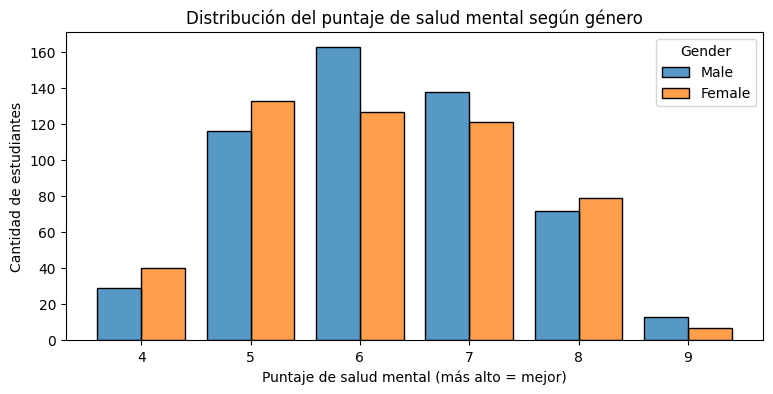

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x="Mental_Health_Score", hue="Gender", multiple="dodge",
             discrete=True, shrink=0.8, ax=ax)
ax.set_title("Distribución del puntaje de salud mental según género")
ax.set_xlabel("Puntaje de salud mental (más alto = mejor)")
ax.set_ylabel("Cantidad de estudiantes")
plt.show()

**Interpretación:** Los puntajes de salud mental de mujeres y varones se reparten de forma muy parecida, van del mismo mínimo, al mismo máximo. En ambos casos la mayoría está entre 5 y 7. Por lo tanto, podemos concluir que **no hay una brecha de género importante en salud mental**.

**Gráfico 2. Comparación entre categorías:** En este grafico vamos a visualizar la siguiente pregunta: ¿qué plataforma se asocia con mejor o peor salud mental?. Para eso realizamos un grafico de barras ordenadas con la cantidad de estudiantes sobre cada una.

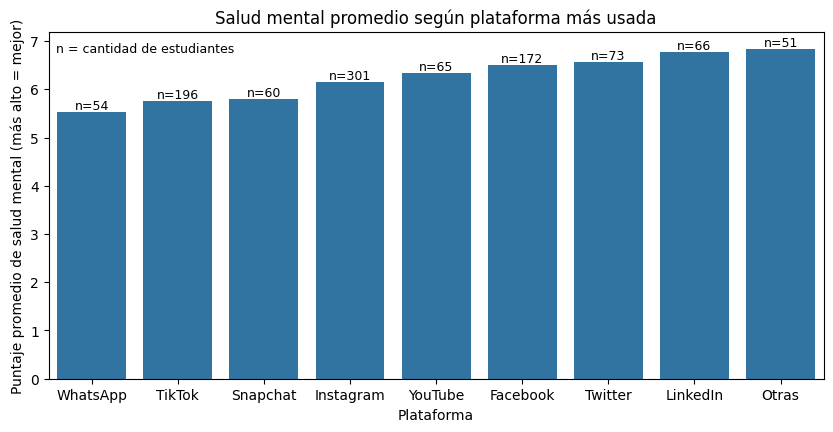

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=por_plataforma.index, y=por_plataforma["salud_mental"], ax=ax)   # una barra por plataforma
for i, fila in enumerate(por_plataforma.itertuples()):
    ax.text(i, fila.salud_mental + 0.05, f"n={fila.estudiantes}", ha="center", fontsize=9)  # cantidad de casos
ax.text(0.01, 0.97, "n = cantidad de estudiantes", transform=ax.transAxes, va="top", fontsize=9)   # definimos que es n para que no haya confusion
ax.set_title("Salud mental promedio según plataforma más usada")
ax.set_xlabel("Plataforma")
ax.set_ylabel("Puntaje promedio de salud mental (más alto = mejor)")
plt.show()

**Interpretación:** Observamos que los usuarios de **WhatsApp, TikTok y Snapchat** son las que peor promedio de salud mental abarcan, y los de **LinkedIn, Twitter, Facebook y el grupo "Otras"** , el mayor. Una posible interpretacion a esto es que las plataformas de uso constante y alta frecuencia se asocian con más horas de pantalla, mientras que las de uso más puntual se asocian con menos. Es una hipotesis, por lo tanto no prueba que la plataforma sea la causa.

Cabe destacar que como el eje arranca en cero, las barras se ven de alturas parecidas y la diferencia no resalta tanto. Pasar de 5,5 a 6,5 (aproximadamente mirando el grafico) se ve como una diferencia chica.

**Gráfico 3. Relación entre dos variables:** Para este grafico, como relacionamos 2 variables, nos hacemos la siguente pregunta: ¿las plataformas donde los estudiantes usan más horas las redes tienen peor salud mental?. Para realizar la visualizacion se usa un **diagrama de dispersión**, en donde cada punto es una plataforma con sus **horas diarias de uso promedio** en el eje horizontal y su **puntaje promedio de salud mental** en el eje vertical. Así podemos observar si ambas variables se mueven juntas.

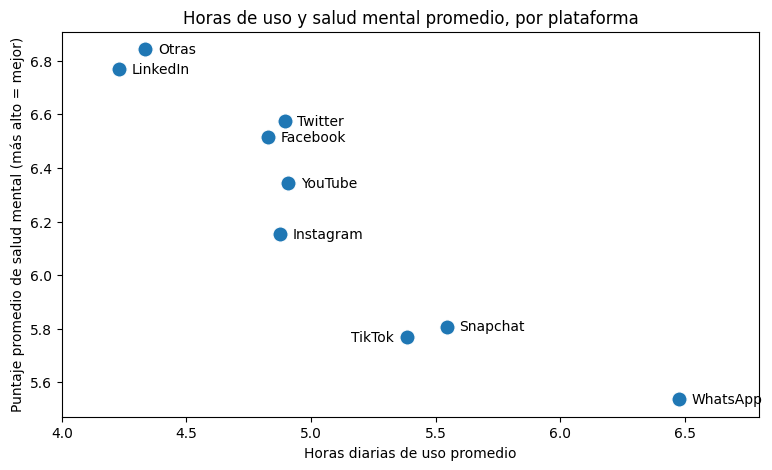

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=por_plataforma, x="uso_horas", y="salud_mental", s=120, ax=ax)   # un punto por plataforma

# Escribimos el nombre de cada plataforma al lado de su punto (TikTok a la izquierda para que no tape a Snapchat)
for nombre, fila in por_plataforma.iterrows():
    izq = nombre == "TikTok"
    ax.annotate(nombre, (fila.uso_horas, fila.salud_mental), textcoords="offset points",
                xytext=(-9 if izq else 9, -3), ha="right" if izq else "left", fontsize=10)

ax.set_xlim(4.0, 6.8)    # margen en el eje horizontal para que entren los nombres
ax.set_title("Horas de uso y salud mental promedio, por plataforma")
ax.set_xlabel("Horas diarias de uso promedio")
ax.set_ylabel("Puntaje promedio de salud mental (más alto = mejor)")
plt.show()

**Interpretación:** Podemos notar que los puntos bajan de izquierda a derecha: cuantas más horas de uso promedio tiene una plataforma, menor es la salud mental promedio de sus estudiantes. **WhatsApp** es la que más horas acumula (6,5 h) y la que peor salud mental tiene (5,54). **TikTok** y **Snapchat** están en el medio de uso (alrededor de 5,4 y 5,5 h) y tienen puntajes bajos de salud mental (5,77 y 5,81). También observamos a **LinkedIn** y **"Otras"**, que tienen el menor uso (alrededor de 4,3 h) y los mejores puntajes de salud mental (6,77 y 6,84).

Con esto podemos concluir que el uso diario y la salud mental están relacionados: las plataformas con peor puntaje de salud mental son también aquellas en las que los estudiantes pasan más horas. Esto no prueba que las horas de uso sean la causa de la peor salud mental, solo muestra que ambas cosas aparecen juntas, es decir, existe una correlación, pero no podemos afirmar que hay causalidad.

---

# Parte 6 | ¿El uso de redes sociales afecta las relaciones sentimentales de los estudiantes?

Esta es la única parte que utiliza la variable `Relationship_Status`. Por ese motivo vuelve a cargar el dataset y, en lugar de eliminar la columna, se queda con las filas que tienen la información completa (`pareja = df.dropna()`).

> **Nota:** la celda de carga de esta parte lee el archivo desde `/content/dataset_final` (ruta de Google Colab). Para ejecutarla es necesario subir el archivo `data/raw/dataset_final` a esa ubicación en Colab o, en un entorno local, contar con el archivo en esa ruta.

## 6.1 | Carga de datos y estado sentimental de los estudiantes

El uso de redes afecta las realaicones de las estudiante?
Primero, importamos las librerias que vamos a usar, agregamos el dataset correspondiete, y hacemos un conteo de los valores que van a encasillar toda esta pregunta (columna "Relationship_Status")

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("/content/dataset_final")
pareja = df.dropna ()
print(pareja["Relationship_Status"].value_counts())
pareja.head()


Relationship_Status
Single             384
In Relationship    289
Complicated         32
Name: count, dtype: int64


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1038,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6.0,In Relationship
1039,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8.0,Single
1040,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5.0,Complicated
1041,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7.0,Single
1042,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6.0,In Relationship


## 6.2 | Uso diario de redes según estado sentimental

luego, calculamos la media y la mediana de las horas de uso diario "Avg_Daily_Usage_Hours" en función a su situación sentimental.

In [ ]:
print(pareja.groupby("Relationship_Status")["Avg_Daily_Usage_Hours"].agg(["mean", "median"]))

                         mean  median
Relationship_Status                  
Complicated          4.721875    4.75
In Relationship      4.930796    4.70
Single               4.926042    4.80


Con los cálculos hechos, sumado al gráfico de abajo, podemos ver que el uso diario de redes sociales son muy parecidos entre, los que estan en pareja, solteros o en una situacion sentimental complicada. Por lo tanto con estos datos no podemos obserbar una que el uso de RRSS afecto en la situacion sentimental de los estudiantes

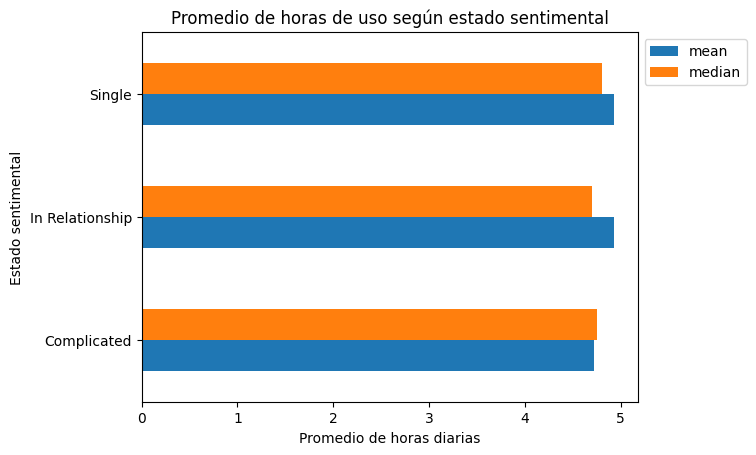

In [ ]:
promedios = pareja.groupby("Relationship_Status")["Avg_Daily_Usage_Hours"].agg(["mean", "median"])
promedios.plot(kind="barh")
plt.title("Promedio de horas de uso según estado sentimental")
plt.ylabel("Estado sentimental")
plt.xlabel("Promedio de horas diarias")
plt.legend(loc="upper left",bbox_to_anchor=(1, 1))

plt.show()

## 6.3 | Estado sentimental según la plataforma más utilizada

In [ ]:
print(pareja["Most_Used_Platform"].value_counts())

Most_Used_Platform
Instagram    249
TikTok       154
Facebook     123
WhatsApp      54
Twitter       30
LinkedIn      21
WeChat        15
Snapchat      13
VKontakte     12
LINE          12
KakaoTalk     12
YouTube       10
Name: count, dtype: int64


Aca hacemos una conteo de cuales son las RRSS mas usadas por los estudiantes segun su situacion sentimental, esto para ver si hay una relacion entre las situacion de los alumnos (pareja, soltero, complicado), y el uso de determinada red social

In [ ]:
pd.crosstab(pareja["Most_Used_Platform"],pareja["Relationship_Status"],normalize="index").mul(100).round(2)

Relationship_Status,Complicated,In Relationship,Single
Most_Used_Platform,,,
Facebook,0.81,57.72,41.46
Instagram,4.02,37.75,58.23
KakaoTalk,0.00,50.00,50.00
LINE,0.00,0.00,100.00
LinkedIn,23.81,38.10,38.10
Snapchat,30.77,30.77,38.46
TikTok,5.19,29.22,65.58
Twitter,0.00,46.67,53.33
VKontakte,0.00,50.00,50.00


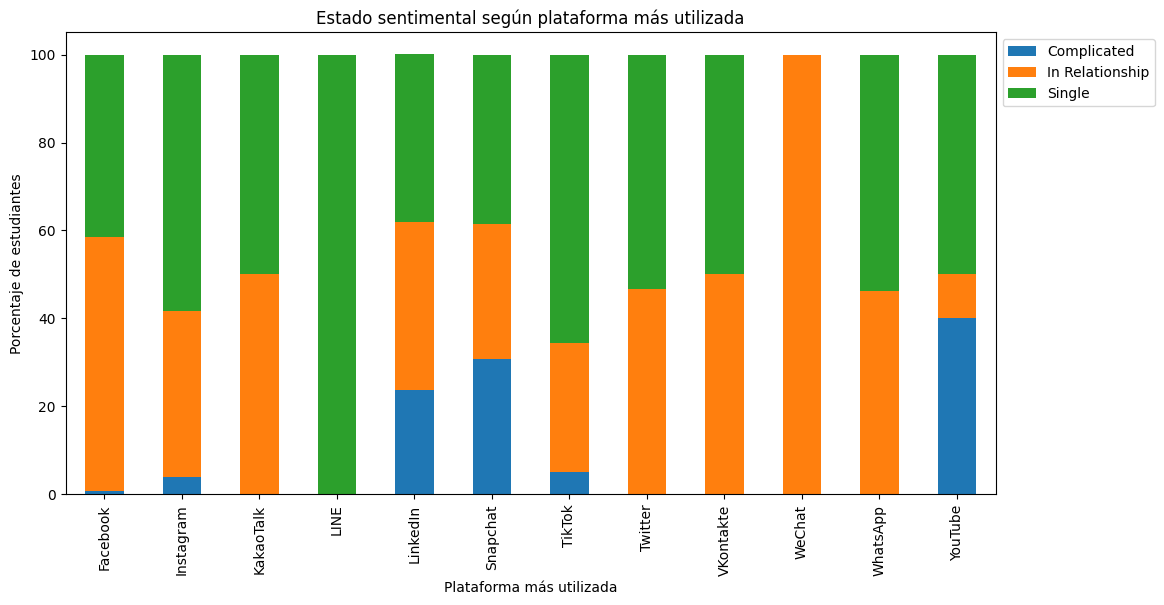

In [ ]:
rrss=pd.crosstab(pareja["Most_Used_Platform"],pareja["Relationship_Status"],normalize="index").mul(100).round(2)
rrss.plot(kind="bar",stacked=True,figsize=(12, 6))
plt.title("Estado sentimental según plataforma más utilizada")
plt.xlabel("Plataforma más utilizada")
plt.ylabel("Porcentaje de estudiantes")
plt.legend(loc="upper left",bbox_to_anchor=(1, 1))
plt.show()

## 6.4 | Análisis sobre las plataformas más usadas

In [ ]:
masusada=pareja["Most_Used_Platform"].value_counts().nlargest(3).index
#masusada[masusada> 100].index
masusada = pareja[pareja["Most_Used_Platform"].isin(masusada)]
print(masusada["Most_Used_Platform"].value_counts())


Most_Used_Platform
Instagram    249
TikTok       154
Facebook     123
Name: count, dtype: int64


Como el dataset tenia datos de algunos lugares donde se usan plataformas con pocas muestras, decidimos hacer el analisis sobre las mas usadas, Instagram, TikTok y Facebook

In [ ]:
pareja["Most_Used_Platform"].value_counts()
pareja

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
1038,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6.0,In Relationship
1040,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5.0,Complicated
1042,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6.0,In Relationship
1043,6,19,Female,Undergraduate,Australia,7.2,Instagram,Yes,4.5,4.0,Complicated
1046,9,18,Male,High School,Japan,4.0,TikTok,No,6.5,7.0,Single
...,...,...,...,...,...,...,...,...,...,...,...
1735,698,24,Male,Graduate,France,4.8,Facebook,No,7.1,7.0,In Relationship
1736,699,19,Female,Undergraduate,Canada,5.7,Instagram,Yes,6.6,6.0,Single
1738,701,20,Female,Undergraduate,Italy,4.7,TikTok,No,7.2,7.0,In Relationship
1739,702,23,Male,Graduate,Russia,6.8,Instagram,Yes,5.9,4.0,Single


In [ ]:
pareja = pareja[pareja["Most_Used_Platform"] != "Twitter"]
pareja = pareja[pareja["Most_Used_Platform"] != "KakaoTalk"]
pareja = pareja[pareja["Most_Used_Platform"] != "LINE"]
pareja = pareja[pareja["Most_Used_Platform"] != "LinkedIn"]
pareja = pareja[pareja["Most_Used_Platform"] != "Snapchat"]
pareja = pareja[pareja["Most_Used_Platform"] != "VKontakte"]
pareja = pareja[pareja["Most_Used_Platform"] != "WeChat"]
pareja = pareja[pareja["Most_Used_Platform"] != "WhatsApp"]
pareja = pareja[pareja["Most_Used_Platform"] != "YouTube"]
pareja.info()


<class 'pandas.core.frame.DataFrame'>
Index: 526 entries, 1038 to 1742
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Student_ID                    526 non-null    int64  
 1   Age                           526 non-null    int64  
 2   Gender                        526 non-null    object 
 3   Academic_Level                526 non-null    object 
 4   Country                       526 non-null    object 
 5   Avg_Daily_Usage_Hours         526 non-null    float64
 6   Most_Used_Platform            526 non-null    object 
 7   Affects_Academic_Performance  526 non-null    object 
 8   Sleep_Hours_Per_Night         526 non-null    float64
 9   Mental_Health_Score           526 non-null    float64
 10  Relationship_Status           526 non-null    object 
dtypes: float64(3), int64(2), object(6)
memory usage: 49.3+ KB


Aca sacamos todas las plataformas que conformaban los dato que parecian escasos para quedarno con las tres antes mencionadas

In [ ]:
pd.crosstab(pareja["Most_Used_Platform"],pareja["Relationship_Status"],normalize="index").mul(100).round(2)

Relationship_Status,Complicated,In Relationship,Single
Most_Used_Platform,,,
Facebook,0.81,57.72,41.46
Instagram,4.02,37.75,58.23
TikTok,5.19,29.22,65.58


por ultimo, sacamos el porcentaje de alumnos ya sea, solteros, en pareja o en situacion complicada, en funcion de las redes que usan.
Podemos ver una clara inclinacion por TikTok e Instagram para los soltero, no solo eso, sino que tambien hay un poircentaje mas alto de estudiantres en situacion complicada en esas dos redes sociales.

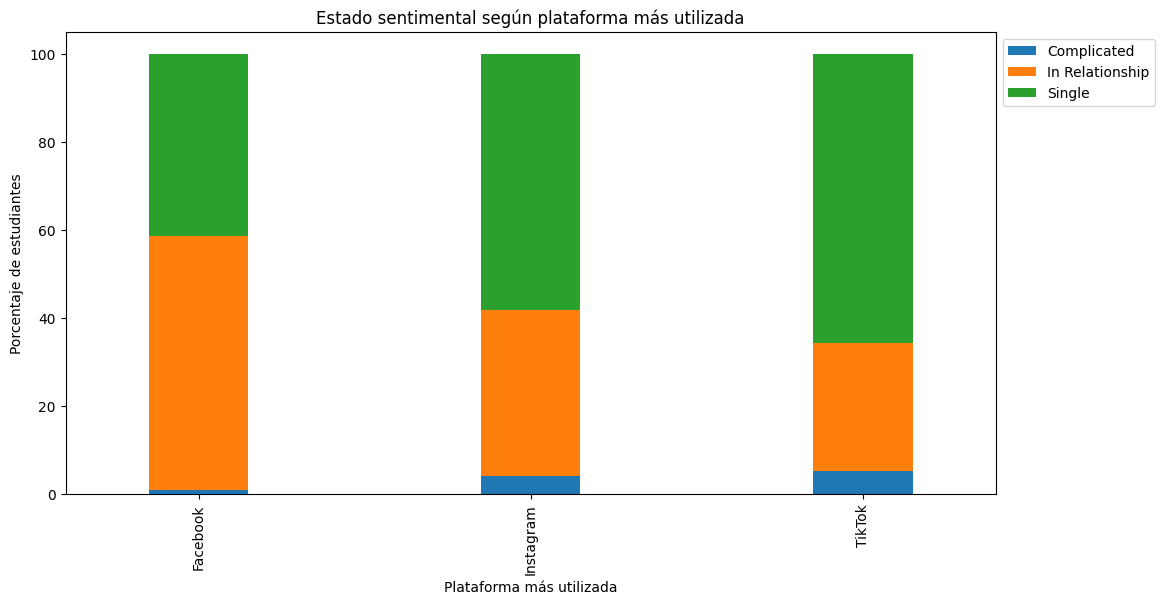

In [ ]:
rrss=pd.crosstab(pareja["Most_Used_Platform"],pareja["Relationship_Status"],normalize="index").mul(100).round(2)
rrss.plot(kind="bar",stacked=True,figsize=(12, 6),width=0.3)
plt.title("Estado sentimental según plataforma más utilizada")
plt.xlabel("Plataforma más utilizada")
plt.ylabel("Porcentaje de estudiantes")
plt.legend(loc="upper left",bbox_to_anchor=(1, 1))
plt.show()

## 6.5 | Conclusión

Con los cálculos hechos, sumado a los gráficos, podemos ver que el uso diario de redes sociales son muy parecidos entre, los que estan en pareja, solteros o en una situacion sentimental complicada. Por lo tanto con estos datos no podemos obserbar una que el uso de RRSS afecto en la situacion sentimental de los estudiantes. A su vez, luego de analizar el estado sentimental de los estudiantes en base a las tres plataformas con más muestras (TikTok, Instagram, Facebook), podemos ver una decantación de los solteros en el uso de Instagram y en menor medida de TikTok.

---

# Parte 7 | Síntesis final

A partir de los distintos análisis realizados sobre el dataset se pueden resumir las siguientes respuestas:

1. **Edad y nivel de desarrollo (Parte 2):** el impacto no es igual para todos. Los estudiantes más jóvenes (18 a 20 años) y los de países en desarrollo presentan, en promedio, más horas de uso, menos horas de sueño, peor salud mental y mayor afectación académica percibida.
2. **Sueño y rendimiento académico (Parte 3):** a mayor uso diario de redes sociales, menos horas de sueño. Los estudiantes que declaran que su desempeño académico se ve perjudicado tienen menos horas de sueño y mayor uso de redes sociales.
3. **Horas por red social y edad (Parte 4):** WhatsApp es la red con mayor promedio de uso diario y TikTok combina muchas observaciones con una mediana de uso elevada. Además, la salud mental decrece a medida que aumenta el uso diario promedio.
4. **Plataformas y género (Parte 5):** hay redes que se asocian con peores resultados (WhatsApp, TikTok y Snapchat) y otras con resultados más favorables (LinkedIn, Twitter y Facebook), aunque gran parte de la diferencia se explica por las horas de uso. La brecha de género es muy leve.
5. **Relaciones sentimentales (Parte 6):** el uso diario de redes es muy parecido entre estudiantes solteros, en pareja o en una situación complicada, por lo que con estos datos no se observa que el uso de redes afecte la situación sentimental.

En todos los casos los resultados son **descriptivos**: muestran asociaciones y diferencias entre grupos dentro de la muestra, pero no permiten establecer relaciones causales.